# [RESEARCH REPORT] Prediksi Harga Saham dengan Multi-Layer Perceptron (MLP)
## Optimasi Bobot Jaringan Menggunakan Remora Optimization Algorithm (ROA) vs Backpropagation (Adam)

**Author:** Bisma Yoga | **Architecture:** MLP (128-64-32) | **Dataset:** Yahoo Finance 5-Year Daily (NVDA, BBCA.JK, TSLA)

**Konfigurasi Eksperimental:**
- **Populasi ROA ($N$):** `20, 100, 200, 300`
- **Iterasi ROA ($T$):** `100, 300`
- **Batas Pencarian (Bounds):** `[-1, 1]`
- **Early Stopping ROA:** Dihentikan jika **MSE validasi** tidak membaik selama **40 iterasi**.
- **Epoch Training Backpropagation (Adam):** `80, 100, 200`


---
## [Ringkasan Eksekutif & Panduan Notebook]

Notebook ini menyajikan implementasi ilmiah komprehensif dari peramalan harga saham menggunakan arsitektur neural network **Multi-Layer Perceptron (MLP 3 Hidden Layers: 128-64-32)** yang dioptimasi menggunakan algoritma metaheuristik mutakhir **Remora Optimization Algorithm (ROA)** (Jia et al., 2021) dan dikomparasikan secara *head-to-head* melawan metode standar industri **Backpropagation (Adam)**.

### Parameter Terstandarisasi (Strict Benchmark Consistency):
- **Populasi Agen ($N$):** 150 agen remora.
- **Maksimum Iterasi ($T$):** 200 iterasi.
- **Rentang Bobot Pencarian ($Bounds$):** `[-1.0, 1.0]`.
- **Dimensi Parameter ($D$):** 18.177 bobot & bias total.
- **Window Size ($W$):** 10 hari bursa ke belakang.
- **Split Dataset:** 70% Train, 15% Validation, 15% Test (Sequential Out-of-Sample).
- **Random Seed:** 67 (Terkontrol penuh untuk reproduktifitas eksperimen).
- **Early Stopping Patience:** 40 iterasi tanpa perbaikan fitness.


In [22]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

print("[*] Seluruh pustaka berhasil dimuat dengan sukses.")

[*] Seluruh pustaka berhasil dimuat dengan sukses.


---
## [Cell 2: Algoritma Metaheuristik Remora Optimization Algorithm (ROA)]

### [Apa yang Dilakukan]:
Cell ini mengimplementasikan algoritma optimasi **Remora Optimization Algorithm (ROA)** yang dipublikasikan oleh **Heming Jia et al. (2021)** sebagai optimizer metaheuristik global untuk Multi-Layer Perceptron (MLP). ROA memodelkan simbiosis komensalisme cerdas ikan remora di lautan lepas yang menumpang pada inang besar (ikan layaran / *Sailfish* dan paus / *Whale*) untuk bernavigasi dan mencari makan.

### [Mekanisme Matematis ROA]:
1. **Host-Switching Dynamic State ($H_i$):**
   Setiap agen remora $i$ memiliki state inang $H_i \in \{0, 1\}$. State $0$ mewakili *Sailfish* (eksplorasi global) dan state $1$ mewakili *Whale* (eksploitasi lokal).
2. **Fase Eksplorasi Global (Free Travel - Sailfish Strategy):**
   $$X_i(t+1) = X_{\text{best}}(t) - \left( r_1 \cdot \left(\frac{X_{\text{best}}(t) + X_{\text{rand}}(t)}{2}\right) - X_{\text{rand}}(t) \right)$$
3. **Fase Eksploitasi Lokal (Eat Thoughtfully - Whale Bubble-net Strategy):**
   $$D = |X_{\text{best}}(t) - X_i(t)|$$
   $$X_i(t+1) = D \cdot \exp(l) \cdot \cos(2\pi l) + X_i(t), \quad l \sim U(-1, 1)$$
4. **Fase Experience Attack & Host Switching:**
   $$X_{\text{att}} = X_i(t) + (X_i(t) - X_{\text{prev}}(t)) \cdot v, \quad v \sim \mathcal{N}(0, 1)$$
   Jika $f(X_{\text{att}}) < f(X_i(t+1))$, remora beralih inang: $H_i = 1 - H_i$.
5. **Fase Host Feeding (Local Fine-Tuning):**
   Jika kandidat posisi tidak memberikan perbaikan fitness, remora mencari makan di sekitar inang:
   $$X_i(t+1) = X_i(t) + A \cdot (X_i(t) - C \cdot X_{\text{best}}(t))$$
   dengan $B_1 = 2(1 - t/T)$, $A = 2 B_1 \cdot r - B_1$, dan $C = 0.1$ (*Remora Factor*).

### [Parameter yang Digunakan]:
- `n_agents` ($N$): **150** (Ukuran populasi remora pada ruang pencarian bobot).
- `max_iter` ($T$): **200** (Jumlah iterasi maksimum pencarian bobot).
- `dim` ($D$): **18,177** (Dimensi ruang pencarian / bobot total MLP).
- `lower_bound` ($lb$): **-1.0** (Batas bawah bobot jaringan).
- `upper_bound` ($ub$): **1.0** (Batas atas bobot jaringan).
- `seed`: **67** (Random seed terkontrol untuk reproduktifitas).
- `C` (*Remora Factor*): **0.1** (Konstanta penskalaan langkah inang Jia et al., 2021).
- `patience`: **40** (Kriteria early stopping jika tidak ada perbaikan fitness).


In [ ]:
class RemoraOptimizationAlgorithm:
    """
    Remora Optimization Algorithm (ROA) - Jia et al. (2021).
    Algoritma Metaheuristik Remora Optimization Algorithm (ROA) dengan parameter konsisten:
    N = 150, Max Iter = 200, Bounds = [-1.0, 1.0], Seed = 67.
    """
    def __init__(self, cost_function, dim, n_agents=150, max_iter=200,
                 lower_bound=-1.0, upper_bound=1.0, seed=67, C=0.1, patience=40,
                 val_cost_function=None):
        self.cost_function = cost_function
        self.val_cost_function = val_cost_function
        self.dim = dim
        self.n_agents = n_agents
        self.max_iter = max_iter
        self.lb = lower_bound
        self.ub = upper_bound
        self.seed = seed
        self.C = C  # Remora Factor
        self.patience = patience
        self.rng = np.random.default_rng(seed)

    def optimize(self):
        population = self.rng.uniform(self.lb, self.ub, size=(self.n_agents, self.dim))
        fitness = np.zeros(self.n_agents)
        for i in range(self.n_agents):
            fitness[i] = self.cost_function(population[i])

        prev_population = population.copy()
        host = self.rng.integers(0, 2, size=self.n_agents)

        best_idx = np.argmin(fitness)
        global_best_cost = fitness[best_idx]
        global_best_pos = population[best_idx].copy()

        if self.val_cost_function is not None:
            best_val_mse = float(self.val_cost_function(global_best_pos))
        else:
            best_val_mse = float(global_best_cost)
        best_val_pos = global_best_pos.copy()

        convergence_curve = np.zeros(self.max_iter)
        val_convergence_curve = np.zeros(self.max_iter)
        patience_counter = 0

        print(f"\n--- Memulai Remora Optimization Algorithm (ROA) ---")
        print(f"[*] Populasi (N): {self.n_agents} | Max Iterasi (T): {self.max_iter} | Dimensi (D): {self.dim}")

        for t in range(self.max_iter):
            B1 = 2.0 * (1.0 - t / self.max_iter)
            sailfish_count = int(np.sum(host == 0))
            whale_count = int(self.n_agents - sailfish_count)
            iter_improved = False

            for i in range(self.n_agents):
                # FASE 1: Pergerakan Inang (Sailfish / Whale)
                if host[i] == 0:
                    r_idx = self.rng.integers(0, self.n_agents)
                    while r_idx == i:
                        r_idx = self.rng.integers(0, self.n_agents)
                    x_rand = population[r_idx]
                    r1 = self.rng.uniform(0, 1, self.dim)
                    new_pos = global_best_pos - (r1 * ((global_best_pos + x_rand) / 2.0) - x_rand)
                else:
                    dist = np.abs(global_best_pos - population[i])
                    l = self.rng.uniform(-1, 1)
                    new_pos = dist * np.exp(l) * np.cos(2.0 * np.pi * l) + population[i]

                new_pos = np.clip(new_pos, self.lb, self.ub)
                new_fit = self.cost_function(new_pos)

                # FASE 2: Experience Attack & Host Switching
                if t > 0:
                    v = self.rng.standard_normal(self.dim)
                    att_pos = population[i] + (population[i] - prev_population[i]) * v
                    att_pos = np.clip(att_pos, self.lb, self.ub)
                    att_fit = self.cost_function(att_pos)
                else:
                    att_fit = float('inf')

                if att_fit < new_fit:
                    cand_pos = att_pos
                    cand_fit = att_fit
                    host[i] = 1 - host[i]
                else:
                    cand_pos = new_pos
                    cand_fit = new_fit

                # FASE 3: Host Feeding
                if cand_fit >= fitness[i]:
                    A = 2.0 * B1 * self.rng.uniform(0, 1) - B1
                    feed_pos = population[i] + A * (population[i] - self.C * global_best_pos)
                    feed_pos = np.clip(feed_pos, self.lb, self.ub)
                    feed_fit = self.cost_function(feed_pos)
                    if feed_fit < cand_fit:
                        cand_pos = feed_pos
                        cand_fit = feed_fit

                # FASE 4: Greedy Update
                if cand_fit < fitness[i]:
                    population[i] = cand_pos
                    fitness[i] = cand_fit
                    if cand_fit < global_best_cost:
                        global_best_cost = cand_fit
                        global_best_pos = cand_pos.copy()
                        iter_improved = True

            prev_population = population.copy()
            convergence_curve[t] = global_best_cost

            if self.val_cost_function is not None:
                current_val_mse = float(self.val_cost_function(global_best_pos))
                val_convergence_curve[t] = current_val_mse
                if current_val_mse < best_val_mse:
                    best_val_mse = current_val_mse
                    best_val_pos = global_best_pos.copy()
                    patience_counter = 0
                else:
                    patience_counter += 1
            else:
                val_convergence_curve[t] = global_best_cost
                if iter_improved:
                    best_val_mse = float(global_best_cost)
                    best_val_pos = global_best_pos.copy()
                    patience_counter = 0
                else:
                    patience_counter += 1

            if (t + 1) % 10 == 0 or t == 0 or (t + 1) == self.max_iter:
                print(f"Iterasi {t+1:03d}/{self.max_iter} | Inang: [Sailfish: {sailfish_count:02d}, Whale: {whale_count:02d}] | Train RMSE: {global_best_cost:.6f} | Val MSE: {val_convergence_curve[t]:.6f}")

            if patience_counter >= self.patience:
                print(f"[*] Early stopping pada iterasi {t+1} (MSE validasi tidak membaik selama {self.patience} iterasi).")
                stop_iteration = t + 1
                convergence_curve = convergence_curve[:stop_iteration]
                val_convergence_curve = val_convergence_curve[:stop_iteration]
                break

        return best_val_pos, best_val_mse, convergence_curve, val_convergence_curve

def run_remora_optimizer(n_agents, max_iter, dim, lower_bound, upper_bound, cost_function, seed=67, C=0.1, patience=40, val_cost_function=None):
    roa = RemoraOptimizationAlgorithm(
        cost_function=cost_function,
        dim=dim,
        n_agents=n_agents,
        max_iter=max_iter,
        lower_bound=lower_bound,
        upper_bound=upper_bound,
        seed=seed,
        C=C,
        patience=patience,
        val_cost_function=val_cost_function
    )
    return roa.optimize()


---
## [Cell 3: Data Acquisition & Preprocessing (Sliding Window & Split Scale)]

### [Apa yang Dilakukan]:
1. `fetch_data`: Mengunduh data historis bursa 5 tahun terakhir menggunakan Yahoo Finance (`yfinance`) dan memfilter 6 fitur utama OHLCV (`Open`, `High`, `Low`, `Close`, `Adj Close`, `Volume`).
2. `create_sliding_window`: Mentransformasikan deret waktu 2D menjadi tensor 3D berbentuk `(samples, window_size, features)` dengan target variabel berupa **Log Return** harga penutupan esok hari: $\ln(Close_{t+1} / Close_t)$.
3. `split_and_scale`: Membagi data secara sekuensial tanpa look-ahead bias menjadi **Train (70%)**, **Validation (15%)**, dan **Test (15%)**, kemudian melakukan normalisasi menggunakan `MinMaxScaler` yang hanya di-*fit* pada data pelatihan (Train).

### [Parameter yang Digunakan]:
- `ticker`: Simbol emiten saham (`NVDA`, `BBCA.JK`, `TSLA`).
- `period`: **"5y"** (5 tahun data historis).
- `interval`: **"1d"** (Frekuensi data harian).
- `columns`: **["Open", "High", "Low", "Close", "Adj Close", "Volume"]** ($N_{\text{features}} = 6$).
- `window_size`: **10** (Jendela observasi 10 hari bursa ke belakang).
- `train_ratio`: **0.70** (70% data latih awal).
- `val_ratio`: **0.15** (15% data validasi tengah).
- `test_ratio`: **0.15** (15% data uji akhir).
- `MinMaxScaler(feature_range=(0, 1))`: Penskalaan normalisasi ke rentang `[0, 1]`.

### [Catatan Konsistensi Benchmark]:
Semua rasio pembagian dataset, formula log-return, dan penskalaan data konsisten 100% sesuai protokol pengujian terstandarisasi.


In [24]:
def fetch_data(ticker, period="5y", interval="1d"):
    df = yf.download(ticker, period=period, interval=interval, auto_adjust=False)
    # Penanganan aman MultiIndex yfinance versi modern
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].dropna()

def create_sliding_window(df, window_size=10):
    """
    Mengubah data tabular menjadi format 3D sliding window.
    Input: df (DataFrame harga OHLCV)
    Output: X (samples, window_size, 6), y (target log return)
    """
    data = df.values
    close_series = df["Close"].values.ravel()
    target = np.log(close_series[1:] / close_series[:-1])  # Log Return sebagai target

    X, y = [], []
    for i in range(window_size, len(data) - 1):
        X.append(data[i - window_size:i, :])  # Jendela 10 hari ke belakang
        y.append(target[i])                   # Prediksi return besok

    return np.array(X), np.array(y).reshape(-1, 1)

def split_and_scale(X, y):
    n = len(X)
    tr_end = int(0.70 * n)
    val_end = int(0.85 * n)

    X_tr, y_tr = X[:tr_end], y[:tr_end]
    X_val, y_val = X[tr_end:val_end], y[tr_end:val_end]
    X_te, y_te = X[val_end:], y[val_end:]

    # Scaling 2D ke 3D (Fit hanya pada Train Set untuk mencegah data leakage)
    n_samples, window, n_feats = X.shape
    sx = MinMaxScaler().fit(X_tr.reshape(-1, n_feats))
    sy = MinMaxScaler().fit(y_tr)

    X_tr_scaled = sx.transform(X_tr.reshape(-1, n_feats)).reshape(X_tr.shape)
    X_val_scaled = sx.transform(X_val.reshape(-1, n_feats)).reshape(X_val.shape)
    X_te_scaled = sx.transform(X_te.reshape(-1, n_feats)).reshape(X_te.shape)

    return (X_tr_scaled, sy.transform(y_tr),
            X_val_scaled, sy.transform(y_val),
            X_te_scaled, sy.transform(y_te), sx, sy)

---
## 🧠 Cell 4: Arsitektur Multi-Layer Perceptron (MLP) & Parameter Unpacking

### 📌 Apa yang Dilakukan:
Cell ini mendefinisikan arsitektur jaringan saraf tiruan (MLP) dengan 3 *hidden layers*, perataan (*flattening*) input temporal, fungsi aktivasi non-linear Tanh, pembongkaran vektor kromosom $\theta$ menjadi bobot/bias jaringan, dan kalkulasi fungsi objektif (*fitness function*) berbasis Root Mean Squared Error (RMSE).

### ⚙️ Parameter yang Digunakan & Nilai Tepatnya:
- `WINDOW_SIZE`: **10** (Panjang jendela waktu input).
- `N_FEATURES`: **6** (Jumlah fitur OHLCV).
- `FLATTEN_SIZE`: **60** ($10 \times 6$).
- **Arsitektur Hidden Layers:**
  - Hidden Layer 1: **128 neuron** (Bobot: $60 \times 128 = 7,680$, Bias: $128 \to 7,808$ parameter)
  - Hidden Layer 2: **64 neuron** (Bobot: $128 \times 64 = 8,192$, Bias: $64 \to 8,256$ parameter)
  - Hidden Layer 3: **32 neuron** (Bobot: $64 \times 32 = 2,048$, Bias: $32 \to 2,080$ parameter)
  - Output Layer: **1 neuron** (Bobot: $32 \times 1 = 32$, Bias: $1 \to 33$ parameter)
- **Total Parameter Dimensi ($D$):** **18,177** parameter yang dioptimasi oleh ROA.
- **Fungsi Aktivasi:** `np.tanh` (Hyperbolic Tangent) pada hidden layers, Linear pada output.
- **Fungsi Fitness:** $\text{RMSE} = \sqrt{\frac{1}{M} \sum_{j=1}^{M} (y_j - \hat{y}_j)^2}$.

### 🔒 Catatan Konsistensi Benchmark:
Arsitektur 128-64-32, ukuran jendela 10, serta total dimensi parameter 18,177 sama persis dengan konfigurasi baseline.

In [ ]:
WINDOW_SIZE = 10
N_FEATURES = 6
FLATTEN_SIZE = WINDOW_SIZE * N_FEATURES

# Perhitungan dimensi parameter total D secara dinamis
w1_params = (FLATTEN_SIZE * 128) + 128
w2_params = (128 * 64) + 64
w3_params = (64 * 32) + 32
w4_params = (32 * 1) + 1

D = w1_params + w2_params + w3_params + w4_params
print(f"[*] Arsitektur MLP: [{FLATTEN_SIZE} -> 128 -> 64 -> 32 -> 1]")
print(f"[*] Total Dimensi Parameter Bobot & Bias (D): {D}")

def unpack(theta):
    """Membongkar vektor 1D theta berukuran D menjadi matriks bobot dan bias MLP."""
    i = 0
    # Layer 1
    W1 = theta[i:i + (FLATTEN_SIZE * 128)].reshape(FLATTEN_SIZE, 128); i += (FLATTEN_SIZE * 128)
    b1 = theta[i:i + 128]; i += 128
    # Layer 2
    W2 = theta[i:i + (128 * 64)].reshape(128, 64); i += (128 * 64)
    b2 = theta[i:i + 64]; i += 64
    # Layer 3
    W3 = theta[i:i + (64 * 32)].reshape(64, 32); i += (64 * 32)
    b3 = theta[i:i + 32]; i += 32
    # Output Layer
    W4 = theta[i:i + 32].reshape(32, 1); i += 32
    b4 = theta[i:i + 1]
    return W1, b1, W2, b2, W3, b3, W4, b4

def mlp_forward(theta, X):
    """Forward pass jaringan MLP menggunakan aktivasi tanh pada hidden layer."""
    X_flat = X.reshape(X.shape[0], -1)
    W1, b1, W2, b2, W3, b3, W4, b4 = unpack(theta)

    h1 = np.tanh(X_flat @ W1 + b1)
    h2 = np.tanh(h1 @ W2 + b2)
    h3 = np.tanh(h2 @ W3 + b3)
    out = h3 @ W4 + b4
    return out

def fitness(theta, X, y):
    """Fungsi fitness: Root Mean Squared Error (RMSE) antara target dan prediksi."""
    mse = np.mean((y - mlp_forward(theta, X)) ** 2)
    return np.sqrt(mse)

def mse_loss(theta, X, y):
    pred = mlp_forward(theta, X)
    return np.mean((y - pred) ** 2)


---
## 🎯 Cell 5: Wrapper Optimasi Remora Optimization Algorithm (`roa_optimize`)

### 📌 Apa yang Dilakukan:
Cell ini membungkus fungsi objektif pelatihan (*training cost function*) dan mengeksekusi optimasi Remora (ROA) untuk mencari bobot global terbaik $\theta^*$ yang meminimalkan RMSE data latih, lalu menghitung skor validasi akhir untuk verifikasi generalisasi.

### ⚙️ Parameter yang Digunakan & Nilai Tepatnya:
- `N` (Population size): **150** (Jumlah remora dalam koloni).
- `T` (Max iterations): **200** (Jumlah siklus iterasi pencarian).
- `bounds`: **(-1.0, 1.0)** (Rentang inisialisasi bobot jaringan).
- `seed`: **67** (Random seed terkontrol).
- `patience`: **40** (Toleransi iterasi tanpa perbaikan).
- `C`: **0.1** (Remora Factor Jia et al., 2021).

### 🔒 Catatan Konsistensi Benchmark:
Parameter $N=150, T=200, \text{seed}=67$ sama persis dengan baseline benchmark kelompok. Disediakan pula alias `po_optimize = roa_optimize` agar antarmuka kompatibel 100%.

In [ ]:
POPULATION_SIZES = [20, 100, 200, 300]
MAX_ITERATIONS = [100, 300]
BOUNDS = (-1.0, 1.0)
EARLY_STOPPING_PATIENCE = 40
BP_EPOCHS = [80, 100, 200]

def create_roa_cost(X, y):
    """Membungkus fungsi fitness agar optimizer hanya perlu memasukkan vektor 'theta'."""
    def cost_function(theta):
        return fitness(theta, X, y)
    return cost_function

def create_roa_mse_cost(X, y):
    """Membungkus fungsi MSE validasi untuk Early Stopping."""
    def val_cost_function(theta):
        return mse_loss(theta, X, y)
    return val_cost_function

create_po_cost = create_roa_cost

def roa_optimize(X_train, y_train, X_val, y_val, N=150, T=200, bounds=BOUNDS, seed=67, patience=EARLY_STOPPING_PATIENCE):
    """
    Menjalankan pelatihan MLP menggunakan Remora Optimization Algorithm (ROA)
    dengan Early Stopping berbasis MSE validasi (patience=40).
    """
    train_cost = create_roa_cost(X_train, y_train)
    val_cost = create_roa_mse_cost(X_val, y_val)

    best_theta, best_val_mse, convergence_curve, val_convergence_curve = run_remora_optimizer(
        n_agents=N,
        max_iter=T,
        dim=D,
        lower_bound=bounds[0],
        upper_bound=bounds[1],
        cost_function=train_cost,
        seed=seed,
        C=0.1,
        patience=patience,
        val_cost_function=val_cost
    )

    print(f"[*] Optimasi ROA Selesai (N={N}, T={T}). Best Val MSE: {best_val_mse:.6f} | Stop@{len(convergence_curve)}/{T}")
    return best_theta, best_val_mse, convergence_curve, val_convergence_curve

po_optimize = roa_optimize


---
## ⚡ Cell 6: Baseline Model Backpropagation (Adam Optimizer)

### 📌 Apa yang Dilakukan:
Cell ini mengimplementasikan model jaringan saraf tiruan pembanding (*baseline*) berbasis algoritma gradien standar **Backpropagation (Adam)** menggunakan PyTorch. Arsitektur layer dan aktivasi dibuat sama persis dengan model ROA: `[60 -> 128 -> 64 -> 32 -> 1]` dengan aktivasi `Tanh`.

### ⚙️ Parameter yang Digunakan & Nilai Tepatnya:
- `epochs`: **200** (Jumlah epoch pelatihan backpropagation).
- `lr` (Learning Rate): **0.01** (Laju pembelajaran optimizer Adam).
- `optimizer`: **torch.optim.Adam**
- `criterion`: **nn.MSELoss()** (Fungsi kerugian kuadrat rata-rata).
- `activation`: **nn.Tanh()** (Aktivasi pada ketiga hidden layer).
- `eval_frequency`: Setiap 10 epoch untuk mencatat validation loss.

### 🔒 Catatan Konsistensi Benchmark:
Arsitektur layer, aktivasi Tanh, learning rate 0.01, dan epoch 200 sama persis dengan baseline benchmark kelompok.

In [ ]:
def train_mlp_backprop(X_train, y_train, X_val, y_val, epochs=200, lr=0.01):
    """Pelatihan baseline MLP menggunakan Backpropagation (Adam) dengan 3 Hidden Layers."""
    torch.manual_seed(67)
    np.random.seed(67)
    X_tr_t = torch.FloatTensor(X_train.reshape(X_train.shape[0], -1))
    y_tr_t = torch.FloatTensor(y_train)
    X_val_t = torch.FloatTensor(X_val.reshape(X_val.shape[0], -1))
    y_val_t = torch.FloatTensor(y_val)

    class MLP(nn.Module):
        def __init__(self):
            super(MLP, self).__init__()
            self.net = nn.Sequential(
                nn.Linear(FLATTEN_SIZE, 128),
                nn.Tanh(),
                nn.Linear(128, 64),
                nn.Tanh(),
                nn.Linear(64, 32),
                nn.Tanh(),
                nn.Linear(32, 1)
            )
        def forward(self, x):
            return self.net(x)

    model = MLP()
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history_mse = []
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        y_pred = model(X_tr_t)
        loss = criterion(y_pred, y_tr_t)
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0 or epoch == epochs - 1:
            model.eval()
            with torch.no_grad():
                val_pred = model(X_val_t)
                val_loss = criterion(val_pred, y_val_t).item()
                history_mse.append(val_loss)

    train_time = time.time() - start_time
    print(f"[*] Pelatihan BP (Adam) Selesai dalam {train_time:.2f} detik. Final Val Loss: {history_mse[-1]:.6f}")
    return model, history_mse, train_time

---
## 🔄 Cell 7: Pipeline Eksekusi Komparatif Terpadu (`run_comparative_pipeline`)

### 📌 Apa yang Dilakukan:
Cell ini mengintegrasikan seluruh alur kerja komparatif untuk satu emiten saham:
1. Mengunduh data OHLCV 5 tahun.
2. Membentuk tensor 3D sliding window ($window=10$).
3. Membagi data menjadi Train (70%), Validation (15%), dan Test (15%).
4. Melatih model **Remora Optimization Algorithm (ROA-MLP)**.
5. Melatih model pembanding **Backpropagation (BP-Adam)**.
6. Merekonstruksi harga saham aktual vs prediksi dari target log-return:
   $$Price_{t} = Price_{t-1} \times \exp(\hat{y}_{\text{log\_return}})$$
7. Menghitung 4 metrik evaluasi standar industri pada data uji (Test Set): **RMSE**, **MAE**, **MAPE (%)**, dan **$R^2$ Score**.

### ⚙️ Parameter yang Digunakan & Nilai Tepatnya:
- `ticker`: Simbol saham (`NVDA`, `BBCA.JK`, `TSLA`).
- `WINDOW_SIZE`: **10**
- `ROA`: $N=150, T=200, seed=67, bounds=(-1.0, 1.0)$.
- `BP`: $epochs=200, lr=0.01$.
- **Metrik Evaluasi:**
  - $\text{RMSE} = \sqrt{\frac{1}{n} \sum (y - \hat{y})^2}$
  - $\text{MAE} = \frac{1}{n} \sum |y - \hat{y}|$
  - $\text{MAPE} = \frac{100\%}{n} \sum \left|\frac{y - \hat{y}}{y}\right|$
  - $R^2 = 1 - \frac{\sum (y - \hat{y})^2}{\sum (y - \bar{y})^2}$

In [ ]:
def run_comparative_pipeline(ticker, pop_sizes=POPULATION_SIZES, max_iters=MAX_ITERATIONS,
                             bounds=BOUNDS, patience=EARLY_STOPPING_PATIENCE, bp_epochs=BP_EPOCHS):
    print(f"\n==================================================")
    print(f"         MEMPROSES SAHAM: {ticker}                ")
    print(f"==================================================")
    df = fetch_data(ticker)

    X, y = create_sliding_window(df, window_size=WINDOW_SIZE)
    print(f"[*] Dimensi tensor X setelah sliding window: {X.shape}")

    close_prices = df["Close"].values[WINDOW_SIZE:].ravel()
    X_tr, y_tr, X_val, y_val, X_te, y_te, sx, sy = split_and_scale(X, y)

    n = len(X)
    val_end = int(0.85 * n)
    close_yesterday_test = close_prices[val_end : -1].ravel()
    close_actual_test = close_prices[val_end + 1 :].ravel()
    X_te_flat_torch = torch.FloatTensor(X_te.reshape(X_te.shape[0], -1))

    def calc_metrics(y_true, y_pred):
        return {
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAE": float(mean_absolute_error(y_true, y_pred)),
            "MAPE": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
            "R2": float(r2_score(y_true, y_pred))
        }

    # 1. Variasi Epoch Backpropagation (Adam): epochs in [80, 100, 200]
    print(f"\n[1/2] Eksperimen Backpropagation (Adam) dengan variasi epochs={bp_epochs}...")
    bp_experiments = []
    best_bp = None

    for ep in bp_epochs:
        print(f"\n>>> Eksperimen BP {ticker} | Epochs={ep}")
        model_bp, bp_log, time_bp = train_mlp_backprop(X_tr, y_tr, X_val, y_val, epochs=ep, lr=0.01)
        model_bp.eval()
        with torch.no_grad():
            y_pred_bp_log_ret = sy.inverse_transform(model_bp(X_te_flat_torch).numpy()).ravel()

        min_len = min(len(close_yesterday_test), len(y_pred_bp_log_ret), len(close_actual_test))
        y_pred_bp_price = (close_yesterday_test[:min_len] * np.exp(y_pred_bp_log_ret[:min_len])).ravel()
        y_true_price = close_actual_test[:min_len].ravel()
        metrics_bp = calc_metrics(y_true_price, y_pred_bp_price)

        bp_record = {
            "epochs": ep,
            "final_val_mse": float(bp_log[-1]),
            "metrics": metrics_bp,
            "time": time_bp,
            "log": bp_log,
            "pred": y_pred_bp_price,
        }
        bp_experiments.append(bp_record)
        print(f"    [Hasil BP Epochs={ep}] Val MSE: {bp_log[-1]:.6f} | Test R2: {metrics_bp['R2']:.4f} | MAPE: {metrics_bp['MAPE']:.2f}% | Waktu: {time_bp:.2f}s")

        if best_bp is None or bp_record["final_val_mse"] < best_bp["final_val_mse"]:
            best_bp = bp_record

    # 2. Eksperimen Grid ROA: N in [20, 100, 200, 300] x T in [100, 300], Bounds=[-1, 1], Patience=40
    print(f"\n[2/2] Eksperimen ROA (N={pop_sizes}, T={max_iters}, Bounds={bounds}, Patience={patience})...")
    experiments = []
    best_exp = None

    for N in pop_sizes:
        for T in max_iters:
            print(f"\n>>> Eksperimen ROA {ticker} | N={N}, T={T}, Bounds={list(bounds)}, Patience={patience}")
            start_roa = time.time()
            theta, best_val_mse, roa_log, roa_val_log = roa_optimize(
                X_tr, y_tr, X_val, y_val,
                N=N, T=T, bounds=bounds, seed=67, patience=patience
            )
            time_roa = time.time() - start_roa

            y_pred_roa_log_ret = sy.inverse_transform(mlp_forward(theta, X_te)).ravel()
            min_len = min(len(close_yesterday_test), len(y_pred_roa_log_ret), len(best_bp["pred"]), len(close_actual_test))
            cy_t = close_yesterday_test[:min_len]
            y_pred_roa_price = (cy_t * np.exp(y_pred_roa_log_ret[:min_len])).ravel()
            y_true_price = close_actual_test[:min_len].ravel()
            metrics_roa = calc_metrics(y_true_price, y_pred_roa_price)

            exp_record = {
                "N": N,
                "T": T,
                "bounds": bounds,
                "stop_iter": len(roa_log),
                "early_stopped": len(roa_log) < T,
                "best_val_mse": float(best_val_mse),
                "metrics": metrics_roa,
                "time": time_roa,
                "log": roa_log,
                "val_log": roa_val_log,
                "pred": y_pred_roa_price,
            }
            experiments.append(exp_record)
            print(f"    [Hasil ROA N={N}, T={T}] Stop@{len(roa_log)}/{T} | Val MSE: {best_val_mse:.6f} | Test R2: {metrics_roa['R2']:.4f} | MAPE: {metrics_roa['MAPE']:.2f}% | Waktu: {time_roa:.2f}s")

            if best_exp is None or exp_record["best_val_mse"] < best_exp["best_val_mse"]:
                best_exp = exp_record

    min_len = min(len(best_exp["pred"]), len(best_bp["pred"]), len(close_actual_test))
    y_true_final = close_actual_test[:min_len].ravel()

    print(f"\n--- Rangkuman Hasil Terbaik {ticker} (ROA N={best_exp['N']}, T={best_exp['T']} vs BP Epochs={best_bp['epochs']}) ---")
    print(f"Waktu ROA : {best_exp['time']:.2f} detik | Waktu BP: {best_bp['time']:.2f} detik")
    print(f"Metrik ROA: {best_exp['metrics']}")
    print(f"Metrik BP : {best_bp['metrics']}")

    return {
        "roa": best_exp,
        "experiments": experiments,
        "eefo": best_exp,
        "bp": best_bp,
        "bp_experiments": bp_experiments,
        "y_true": y_true_final
    }


---
## [Cell 8: Utilitas Visualisasi Komparatif & Ekspor Data Penelitian]

### [Apa yang Dilakukan]:
Cell ini mendefinisikan generator grafik visualisasi komparatif beresolusi tinggi (200 DPI) yang dirancang khusus untuk kemudahan presentasi sidang/seminar akademik serta ekspor data riset lengkap:
1. **Executive Performance Dashboard (`executive_performance_dashboard.png`):** Diagram batang terkelompok (*grouped bar chart*) membandingkan metrik $R^2$ Score dan MAPE (%) antara ROA-MLP vs Backpropagation (Adam) untuk seluruh aset. Sangat efektif sebagai slide pembuka presentasi.
2. **Actual vs Predicted Overlaid Time-Series (`actual_vs_predicted_time_series.png`):** Menampilkan harga aktual vs prediksi ROA vs Backpropagation dalam satu kanvas grafik terintegrasi per saham lengkap dengan label evaluasi metrik dan status pemenang.
3. **Regression Scatter Parity Plot (`regression_scatter_parity.png`):** Plot sebaran paritas ($y_{\text{true}}$ vs $\hat{y}_{\text{pred}}$) terhadap garis ideal diagonal 45 derajat ($y = x$) untuk membuktikan linearitas dan kualitas penyesuaian regresi.
4. **Dinamika Konvergensi Teranotasi (`roa_vs_backprop_convergence_clarified.png`):** Kurva fitness loss (MSE skala log) terhadap iterasi nyata, dilengkapi anotasi titik *Early Stopping* dan penjelasan konvergensi cepat ROA.
5. `export_research_data_to_csv`: Mengekspor data metrik evaluasi, prediksi harian per sampel, dan riwayat konvergensi ke berkas CSV terstruktur.

### [Parameter yang Digunakan]:
- `dpi`: **200** (Resolusi tinggi untuk publikasi & slide presentasi).
- Berkas Output Gambar:
  - `executive_performance_dashboard.png`
  - `actual_vs_predicted_time_series.png` (alias: `actual_vs_predicted_roa_3assets.png`)
  - `regression_scatter_parity.png`
  - `roa_vs_backprop_convergence_clarified.png` (alias: `roa_vs_backprop_convergence_3assets.png`)
- Berkas Output CSV:
  - `evaluation_metrics_summary_roa.csv`
  - `actual_vs_predicted_forecasts_roa.csv`
  - `training_convergence_history_roa.csv`


In [ ]:
def generate_comparative_plots(results_compare, tickers):
    """
    Menghasilkan 4 set grafik visualisasi komparatif beresolusi tinggi (200 DPI)
    yang dirancang khusus agar mudah dipresentasikan dalam sidang/seminar akademik:
    1. Executive Performance Dashboard (Bar Chart R2 & MAPE - Slide Ringkasan)
    2. Actual vs Predicted Overlaid Time-Series (Perbandingan Langsung dalam 1 Plot)
    3. Regression Scatter Parity Plot (Titik sebaran vs Garis Ideal 45 Derajat y = x)
    4. Dinamika Konvergensi Teranotasi Early Stopping (Iterasi Riil & Alasan Konvergensi)
    """
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'axes.facecolor': '#FAFAFA',
        'figure.facecolor': '#FFFFFF',
        'axes.grid': True,
        'grid.color': '#E5E7EB',
        'grid.linestyle': '--',
        'grid.alpha': 0.7,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.edgecolor': '#9CA3AF',
        'axes.linewidth': 1.1,
        'font.size': 10
    })

    COLOR_ACTUAL = '#0F172A'  # Hitam arang ground truth
    COLOR_ROA = '#2563EB'     # Biru royal ROA-MLP
    COLOR_BP = '#EA580C'      # Oranye/Amber Backprop-Adam

    # =========================================================================
    # 1. EXECUTIVE PERFORMANCE DASHBOARD (Slide 1: Ringkasan Eksekutif)
    # =========================================================================
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    x = np.arange(len(tickers))
    width = 0.35

    r2_roa = [results_compare[t]["roa"]["metrics"]["R2"] for t in tickers]
    r2_bp = [results_compare[t]["bp"]["metrics"]["R2"] for t in tickers]

    rects1 = axes[0].bar(x - width/2, r2_roa, width, label='Remora Optimization (ROA-MLP)', color=COLOR_ROA, alpha=0.9, edgecolor='#1D4ED8')
    rects2 = axes[0].bar(x + width/2, r2_bp, width, label='Backpropagation (Adam-MLP)', color=COLOR_BP, alpha=0.85, edgecolor='#C2410C')

    axes[0].set_title(r"Akurasi Regresi ($R^2$ Score) — Semakin Tinggi Semakin Baik", fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(tickers, fontsize=11, fontweight='bold')
    axes[0].set_ylabel(r"Koefisien Determinasi ($R^2$)", fontsize=11)
    axes[0].axhline(0, color='#6B7280', linestyle='-', linewidth=0.8)
    axes[0].legend(loc='lower right', frameon=True, facecolor='#FFFFFF', edgecolor='#E5E7EB')

    for rect in rects1:
        h = rect.get_height()
        y_pos = h + (0.04 if h >= 0 else -0.2)
        axes[0].annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width() / 2, y_pos),
                         ha='center', va='bottom' if h >= 0 else 'top', fontsize=9.5, fontweight='bold', color=COLOR_ROA)

    for rect in rects2:
        h = rect.get_height()
        y_pos = h + (0.04 if h >= 0 else -0.2)
        axes[0].annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width() / 2, y_pos),
                         ha='center', va='bottom' if h >= 0 else 'top', fontsize=9.5, fontweight='bold', color=COLOR_BP)

    mape_roa = [results_compare[t]["roa"]["metrics"]["MAPE"] for t in tickers]
    mape_bp = [results_compare[t]["bp"]["metrics"]["MAPE"] for t in tickers]

    rects3 = axes[1].bar(x - width/2, mape_roa, width, label='Remora Optimization (ROA-MLP)', color=COLOR_ROA, alpha=0.9, edgecolor='#1D4ED8')
    rects4 = axes[1].bar(x + width/2, mape_bp, width, label='Backpropagation (Adam-MLP)', color=COLOR_BP, alpha=0.85, edgecolor='#C2410C')

    axes[1].set_title("Tingkat Kesalahan Prediksi (MAPE %) — Semakin Rendah Semakin Baik", fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(tickers, fontsize=11, fontweight='bold')
    axes[1].set_ylabel("Mean Absolute Percentage Error (%)", fontsize=11)
    axes[1].legend(loc='upper right', frameon=True, facecolor='#FFFFFF', edgecolor='#E5E7EB')

    for rect in rects3:
        h = rect.get_height()
        axes[1].annotate(f"{h:.2f}%", xy=(rect.get_x() + rect.get_width() / 2, h + 0.3),
                         ha='center', va='bottom', fontsize=9.5, fontweight='bold', color=COLOR_ROA)

    for rect in rects4:
        h = rect.get_height()
        axes[1].annotate(f"{h:.2f}%", xy=(rect.get_x() + rect.get_width() / 2, h + 0.3),
                         ha='center', va='bottom', fontsize=9.5, fontweight='bold', color=COLOR_BP)

    plt.suptitle("Executive Summary: Performa Prediksi ROA-MLP vs BP-Adam", fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig("executive_performance_dashboard.png", dpi=200, bbox_inches='tight')
    plt.close()

    # =========================================================================
    # 2. TIME-SERIES ACTUAL VS PREDICTED (Slide 2: Overlaid Tracking)
    # =========================================================================
    fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=False)
    for i, ticker in enumerate(tickers):
        y_true = results_compare[ticker]["y_true"]
        y_roa = results_compare[ticker]["roa"]["pred"]
        y_bp = results_compare[ticker]["bp"]["pred"]

        r2_roa = results_compare[ticker]['roa']['metrics']['R2']
        mape_roa = results_compare[ticker]['roa']['metrics']['MAPE']
        rmse_roa = results_compare[ticker]['roa']['metrics']['RMSE']

        r2_bp = results_compare[ticker]['bp']['metrics']['R2']
        mape_bp = results_compare[ticker]['bp']['metrics']['MAPE']
        rmse_bp = results_compare[ticker]['bp']['metrics']['RMSE']

        winner_badge = "[WINNER: ROA Lebih Akurat]" if r2_roa > r2_bp else "[Adam Lebih Baik]"
        badge_border = "#15803D" if r2_roa > r2_bp else "#B45309"

        axes[i].plot(y_true, label="Harga Aktual (Ground Truth)", color=COLOR_ACTUAL, linewidth=2.4, zorder=3)
        axes[i].plot(y_roa, label=f"Remora Optimization (ROA)  [R²={r2_roa:.4f}, MAPE={mape_roa:.2f}%]", color=COLOR_ROA, linewidth=2.0, linestyle='-', zorder=4)
        axes[i].plot(y_bp, label=f"Backpropagation (Adam)     [R²={r2_bp:.4f}, MAPE={mape_bp:.2f}%]", color=COLOR_BP, linewidth=1.7, linestyle='--', zorder=2)

        axes[i].fill_between(range(len(y_true)), y_true, y_roa, alpha=0.10, color=COLOR_ROA, label="Area Deviasi ROA")

        currency = "IDR" if "JK" in ticker else "USD"
        axes[i].set_title(f"Saham: {ticker} — Perbandingan Prediksi Tren Harga Out-of-Sample", fontsize=13, fontweight='bold', loc='left', pad=10)
        axes[i].set_xlabel("Sampel Hari Uji (Test Index)", fontsize=10)
        axes[i].set_ylabel(f"Harga ({currency})", fontsize=10)
        axes[i].legend(loc='upper left', frameon=True, facecolor='#FFFFFF', edgecolor='#D1D5DB', fontsize=9.5)

        stat_box = (
            f"Evaluasi Metrik {ticker}:\n"
            f"• ROA-MLP : RMSE={rmse_roa:.2f} | R²={r2_roa:.4f} | MAPE={mape_roa:.2f}%\n"
            f"• BP-Adam : RMSE={rmse_bp:.2f} | R²={r2_bp:.4f} | MAPE={mape_bp:.2f}%\n"
            f"Status: {winner_badge}"
        )
        axes[i].text(0.98, 0.08, stat_box, transform=axes[i].transAxes, fontsize=9.5,
                     verticalalignment='bottom', horizontalalignment='right',
                     bbox=dict(boxstyle='round,pad=0.5', facecolor='#F8FAFC', edgecolor=badge_border, linewidth=1.3))

    plt.suptitle("Perbandingan Prediksi Harga Saham pada Test Set: ROA-MLP vs BP-Adam", fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig("actual_vs_predicted_time_series.png", dpi=200, bbox_inches='tight')
    plt.savefig("actual_vs_predicted_roa_3assets.png", dpi=200, bbox_inches='tight')
    plt.close()

    # =========================================================================
    # 3. REGRESSION SCATTER / PARITY PLOT (Slide 3: Garis Diagonal 45 Derajat)
    # =========================================================================
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    for i, ticker in enumerate(tickers):
        y_true = results_compare[ticker]["y_true"]
        y_roa = results_compare[ticker]["roa"]["pred"]
        y_bp = results_compare[ticker]["bp"]["pred"]
        r2_roa = results_compare[ticker]['roa']['metrics']['R2']
        r2_bp = results_compare[ticker]['bp']['metrics']['R2']

        axes[i].scatter(y_true, y_roa, color=COLOR_ROA, alpha=0.6, s=28, label=f"ROA-MLP (R² = {r2_roa:.3f})", edgecolor='none')
        axes[i].scatter(y_true, y_bp, color=COLOR_BP, alpha=0.45, s=24, marker='^', label=f"BP-Adam (R² = {r2_bp:.3f})", edgecolor='none')

        min_val = min(np.min(y_true), np.min(y_roa), np.min(y_bp))
        max_val = max(np.max(y_true), np.max(y_roa), np.max(y_bp))
        axes[i].plot([min_val, max_val], [min_val, max_val], color='#DC2626', linestyle='--', linewidth=1.8, label="Garis Ideal Paritas (y = x)")

        axes[i].set_title(rf"{ticker}: Parity Scatter ($y_{{actual}}$ vs $\hat{{y}}_{{pred}}$)", fontsize=12, fontweight='bold', pad=10)
        axes[i].set_xlabel(r"Harga Aktual ($y_{true}$)", fontsize=10)
        axes[i].set_ylabel(r"Harga Prediksi ($\hat{y}$)", fontsize=10)
        axes[i].legend(loc='upper left', frameon=True, facecolor='#FFFFFF', edgecolor='#E5E7EB', fontsize=9)

    plt.suptitle("Analisis Paritas Regresi (Titik Merapat ke Garis 45 Derajat Menandakan Prediksi Sangat Akurat)", fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig("regression_scatter_parity.png", dpi=200, bbox_inches='tight')
    plt.close()

    # =========================================================================
    # 4. CONVERGENCE DYNAMICS WITH EARLY STOPPING ANNOTATION (Slide 4)
    # =========================================================================
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
    for i, ticker in enumerate(tickers):
        roa_curve = results_compare[ticker]["roa"]["log"]
        bp_curve = results_compare[ticker]["bp"]["log"]

        iters_roa = np.arange(1, len(roa_curve) + 1)
        iters_bp = np.arange(1, len(bp_curve) + 1)

        axes[i].plot(iters_roa, roa_curve, label=f"Remora Optimization (ROA) [{len(roa_curve)} iterasi]", color=COLOR_ROA, linewidth=2.2)
        axes[i].plot(iters_bp, bp_curve, label=f"Backpropagation (Adam) [{len(bp_curve)} iterasi]", color=COLOR_BP, linestyle='--', linewidth=1.8)

        stop_iter = len(roa_curve)
        best_loss = min(roa_curve)
        if stop_iter < 200:
            axes[i].axvline(x=stop_iter, color='#DC2626', linestyle=':', linewidth=1.5, alpha=0.85)
            axes[i].scatter([stop_iter], [roa_curve[-1]], color='#DC2626', s=40, zorder=5, label=f"Early Stop (Iter {stop_iter})")
            axes[i].annotate(
                f"Early Stopping Terpicu\nIterasi {stop_iter} | Loss: {best_loss:.4e}",
                xy=(stop_iter, roa_curve[-1]),
                xytext=(-60, 25),
                textcoords="offset points",
                arrowprops=dict(arrowstyle="->", color='#DC2626', lw=1.2, shrinkB=4),
                fontsize=8.5,
                fontweight='bold',
                color='#991B1B',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#FEF2F2', edgecolor='#FCA5A5')
            )

        axes[i].set_title(f"{ticker}: Dinamika Konvergensi Fitness Loss", fontsize=12, fontweight='bold', pad=10)
        axes[i].set_xlabel("Iterasi Riil (Actual Iteration / Epoch)", fontsize=10)
        axes[i].set_ylabel("Fitness Loss (MSE Skala Log)", fontsize=10)
        axes[i].set_yscale("log")
        axes[i].legend(loc='upper right', frameon=True, facecolor='#FFFFFF', edgecolor='#E5E7EB', fontsize=9)

    plt.suptitle("Kurva Konvergensi Pelatihan: ROA-MLP vs Backpropagation (Adam)", fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig("roa_vs_backprop_convergence_clarified.png", dpi=200, bbox_inches='tight')
    plt.savefig("roa_vs_backprop_convergence_3assets.png", dpi=200, bbox_inches='tight')
    plt.close()
    print("[+] Seluruh visualisasi komparatif presentasi berhasil disimpan.")

def export_research_data_to_csv(results_compare, tickers):
    print("\n[*] Mengekspor seluruh data metrik dan prediksi ke CSV...")

    metrics_data = []
    for ticker in tickers:
        for method in ["roa", "bp"]:
            metrics = results_compare[ticker][method]["metrics"]
            metrics_data.append({
                "Ticker": ticker,
                "Method": "Remora Optimization (ROA)" if method == "roa" else "Backprop (Adam)",
                "RMSE": metrics["RMSE"],
                "MAE": metrics["MAE"],
                "MAPE (%)": metrics["MAPE"],
                "R2_Score": metrics["R2"],
                "Training_Time_Sec": results_compare[ticker][method]["time"]
            })
    pd.DataFrame(metrics_data).to_csv("evaluation_metrics_summary_roa.csv", index=False)

    forecast_data = []
    for ticker in tickers:
        y_true = results_compare[ticker]["y_true"].ravel()
        y_roa = results_compare[ticker]["roa"]["pred"].ravel()
        y_bp = results_compare[ticker]["bp"]["pred"].ravel()

        df_ticker = pd.DataFrame({
            "Ticker": ticker,
            "Test_Sample_Idx": range(1, len(y_true) + 1),
            "Actual_Price": y_true,
            "ROA_Predicted_Price": y_roa,
            "Backprop_Predicted_Price": y_bp
        })
        forecast_data.append(df_ticker)
    pd.concat(forecast_data, ignore_index=True).to_csv("actual_vs_predicted_forecasts_roa.csv", index=False)

    convergence_data = []
    for ticker in tickers:
        roa_log = results_compare[ticker]["roa"]["log"]
        convergence_data.append(pd.DataFrame({
            "Ticker": ticker, "Method": "Remora Optimization (ROA)",
            "Iteration": range(1, len(roa_log) + 1), "Loss": roa_log
        }))

        bp_log = results_compare[ticker]["bp"]["log"]
        convergence_data.append(pd.DataFrame({
            "Ticker": ticker, "Method": "Backprop (Adam)",
            "Logged_Step": range(1, len(bp_log) + 1), "Loss": bp_log
        }))
    pd.concat(convergence_data, ignore_index=True).to_csv("training_convergence_history_roa.csv", index=False)
    print("[+] Seluruh berkas CSV berhasil diekspor.")


def plot_experimental_grid(results_compare, tickers):
    """Visualisasi heatmap eksperimen grid ROA (N vs T) untuk setiap saham."""
    n_tickers = len(tickers)
    fig, axes = plt.subplots(1, n_tickers, figsize=(6 * n_tickers, 4.8))
    if n_tickers == 1:
        axes = [axes]

    for i, ticker in enumerate(tickers):
        exps = results_compare[ticker].get("experiments", [])
        if not exps:
            continue
        df_exp = pd.DataFrame([
            {"N": e["N"], "T": e["T"], "MAPE": e["metrics"]["MAPE"], "R2": e["metrics"]["R2"], "Stop": e["stop_iter"]}
            for e in exps
        ])
        pivot_mape = df_exp.pivot(index="N", columns="T", values="MAPE")
        pivot_r2 = df_exp.pivot(index="N", columns="T", values="R2")
        pivot_stop = df_exp.pivot(index="N", columns="T", values="Stop")

        axes[i].imshow(pivot_mape.values, cmap="YlGnBu_r", aspect="auto")
        axes[i].set_xticks(range(len(pivot_mape.columns)))
        axes[i].set_xticklabels([f"T={t}" for t in pivot_mape.columns], fontweight="bold")
        axes[i].set_yticks(range(len(pivot_mape.index)))
        axes[i].set_yticklabels([f"N={n}" for n in pivot_mape.index], fontweight="bold")
        axes[i].set_title(f"{ticker}\nTest MAPE (%), R2 & Stop Iter", fontweight="bold")

        for r in range(len(pivot_mape.index)):
            for c in range(len(pivot_mape.columns)):
                val = pivot_mape.values[r, c]
                r2v = pivot_r2.values[r, c]
                stp = int(pivot_stop.values[r, c])
                axes[i].text(c, r, f"MAPE: {val:.2f}%\nR2: {r2v:.3f}\n(stop@{stp})", ha="center", va="center",
                             color="#0F172A", fontsize=8.5, fontweight="bold")

    plt.suptitle("Eksperimen Grid ROA: Populasi (N) vs Iterasi (T) — Bounds [-1, 1], Early Stopping Patience=40",
                 fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.savefig("roa_experimental_grid_heatmap.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("[+] Heatmap eksperimen grid ROA berhasil disimpan ke roa_experimental_grid_heatmap.png.")

def plot_variations_analysis(results_compare, tickers):
    """Visualisasi analisis seluruh variasi ROA (N x T) vs Backpropagation (Epochs 80, 100, 200)."""
    n_tickers = len(tickers)
    fig, axes = plt.subplots(n_tickers, 3, figsize=(20, 4.8 * n_tickers))
    if n_tickers == 1:
        axes = np.array([axes])

    for i, ticker in enumerate(tickers):
        roa_exps = results_compare[ticker].get("experiments", [])
        bp_exps = results_compare[ticker].get("bp_experiments", [])

        labels = [f"ROA\nN{e['N']}-T{e['T']}" for e in roa_exps] + [f"BP\nE{b['epochs']}" for b in bp_exps]
        r2_vals = [e["metrics"]["R2"] for e in roa_exps] + [b["metrics"]["R2"] for b in bp_exps]
        mape_vals = [e["metrics"]["MAPE"] for e in roa_exps] + [b["metrics"]["MAPE"] for b in bp_exps]
        time_vals = [e["time"] for e in roa_exps] + [b["time"] for b in bp_exps]
        colors = ["#2563EB"] * len(roa_exps) + ["#EA580C"] * len(bp_exps)
        x = np.arange(len(labels))

        # Panel 1: R2 Score
        axes[i, 0].bar(x, r2_vals, color=colors, edgecolor="#0F172A", linewidth=0.6)
        axes[i, 0].set_title(f"{ticker} — R2 Score (Lebih Tinggi Lebih Baik)", fontweight="bold")
        axes[i, 0].set_xticks(x)
        axes[i, 0].set_xticklabels(labels, fontsize=7.5, rotation=25)
        axes[i, 0].axhline(0, color="#64748B", linewidth=0.8, linestyle="--")

        # Panel 2: MAPE (%)
        axes[i, 1].bar(x, mape_vals, color=colors, edgecolor="#0F172A", linewidth=0.6)
        axes[i, 1].set_title(f"{ticker} — MAPE % (Lebih Rendah Lebih Baik)", fontweight="bold")
        axes[i, 1].set_xticks(x)
        axes[i, 1].set_xticklabels(labels, fontsize=7.5, rotation=25)

        # Panel 3: Runtime (s)
        axes[i, 2].bar(x, time_vals, color=colors, edgecolor="#0F172A", linewidth=0.6)
        axes[i, 2].set_title(f"{ticker} — Waktu Training (Detik)", fontweight="bold")
        axes[i, 2].set_xticks(x)
        axes[i, 2].set_xticklabels(labels, fontsize=7.5, rotation=25)

    plt.suptitle("Analisis Lengkap Seluruh Variasi: ROA (N=[20,100,200,300], T=[100,300]) vs BP (Epochs=[80,100,200])",
                 fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig("variations_comparison_analysis.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("[+] Grafik analisis seluruh variasi berhasil disimpan ke variations_comparison_analysis.png.")

def export_experimental_grid_csv(results_compare, tickers):
    exp_rows = []
    bp_rows = []
    for ticker in tickers:
        for e in results_compare[ticker].get("experiments", []):
            exp_rows.append({
                "Ticker": ticker,
                "Population_N": e["N"],
                "Max_Iter_T": e["T"],
                "Bounds": f"[{e['bounds'][0]}, {e['bounds'][1]}]",
                "Stop_Iteration": e["stop_iter"],
                "Early_Stopped": e["early_stopped"],
                "Best_Val_MSE": e["best_val_mse"],
                "Test_RMSE": e["metrics"]["RMSE"],
                "Test_MAE": e["metrics"]["MAE"],
                "Test_MAPE (%)": e["metrics"]["MAPE"],
                "Test_R2": e["metrics"]["R2"],
                "Training_Time_Sec": e["time"]
            })
        for b in results_compare[ticker].get("bp_experiments", []):
            bp_rows.append({
                "Ticker": ticker,
                "Epochs": b["epochs"],
                "Final_Val_MSE": b["final_val_mse"],
                "Test_RMSE": b["metrics"]["RMSE"],
                "Test_MAE": b["metrics"]["MAE"],
                "Test_MAPE (%)": b["metrics"]["MAPE"],
                "Test_R2": b["metrics"]["R2"],
                "Training_Time_Sec": b["time"]
            })
    if exp_rows:
        pd.DataFrame(exp_rows).to_csv("roa_experimental_grid_results.csv", index=False)
        print("[+] Rekap eksperimen grid ROA diekspor ke roa_experimental_grid_results.csv.")
    if bp_rows:
        pd.DataFrame(bp_rows).to_csv("bp_experimental_results.csv", index=False)
        print("[+] Rekap eksperimen variasi epoch BP diekspor ke bp_experimental_results.csv.")


---
## 🚀 Cell 9: Eksekusi Utama Pengujian (Main Experiment Execution)

### 📌 Apa yang Dilakukan:
Cell ini menjalankan seluruh eksperimen komparasi untuk ketiga emiten saham:
1. `NVDA` (NVIDIA Corporation — Sektor Semikonduktor & AI, volatilitas tinggi, tren bullish kuat).
2. `BBCA.JK` (PT Bank Central Asia Tbk — Sektor Perbankan Indonesia, likuiditas tinggi, pasar berkembang IDX).
3. `TSLA` (Tesla Inc. — Sektor EV & Teknologi, volatilitas tinggi, fluktuasi tajam).

### ⚙️ Parameter yang Digunakan & Nilai Tepatnya:
- `tickers_to_test`: **["NVDA", "BBCA.JK", "TSLA"]** (3 emiten target).
- `N`: **150**
- `T`: **200**
- `seed`: **67**
- `epochs`: **200**
- `lr`: **0.01**

In [ ]:
if __name__ == "__main__":
    tickers_to_test = ["NVDA", "BBCA.JK", "TSLA"]
    results_compare = {}

    for ticker in tickers_to_test:
        results_compare[ticker] = run_comparative_pipeline(ticker)

    generate_comparative_plots(results_compare, tickers_to_test)
    plot_experimental_grid(results_compare, tickers_to_test)
    plot_variations_analysis(results_compare, tickers_to_test)
    export_research_data_to_csv(results_compare, tickers_to_test)
    export_experimental_grid_csv(results_compare, tickers_to_test)


---
## 📋 Cell 10: Rekapitulasi Tabel Hasil & Metrik Komparatif (ROA vs BP)

### 📌 Apa yang Dilakukan:
Cell ini merangkum seluruh metrik evaluasi pada Test Set dalam bentuk tabel Pandas terstruktur dan profesional. Metrik mencakup:
- **RMSE (Root Mean Squared Error):** Mengukur deviasi kesalahan kuadrat rata-rata (satuan mata uang).
- **MAE (Mean Absolute Error):** Rata-rata selisih absolut antara nilai riil dan prediksi.
- **MAPE (%):** Rata-rata persentase kesalahan relatif (semakin kecil < 5%, model semakin superior).
- **$R^2$ Score (Koefisien Determinasi):** Proporsi varians data aktual yang mampu dijelaskan model (nilai mendekati 1.0 = sempurna).
- **Training Time (detik):** Efisiensi komputasi pelatihan model.

### ⚙️ Parameter yang Digunakan:
- Input: Objek `results_compare` hasil eksekusi ketiga emiten.
- Format Tampilan: Pandas DataFrame dengan styling presisi desimal 4 angka di belakang koma.

In [ ]:
# --- PEMBUATAN TABEL REKAPITULASI HASIL KOMPARATIF ---
metrics_summary_list = []
roa_var_rows = []
bp_var_rows = []

for ticker in tickers_to_test:
    res_roa = results_compare[ticker]["roa"]["metrics"]
    t_roa = results_compare[ticker]["roa"]["time"]
    n_best = results_compare[ticker]["roa"].get("N", "-")
    iter_best = results_compare[ticker]["roa"].get("T", "-")

    res_bp = results_compare[ticker]["bp"]["metrics"]
    t_bp = results_compare[ticker]["bp"]["time"]
    ep_best = results_compare[ticker]["bp"].get("epochs", "-")

    metrics_summary_list.append({
        "Ticker": ticker,
        "Metode": f"ROA Terbaik (N={n_best}, T={iter_best})",
        "RMSE": f"{res_roa['RMSE']:.4f}",
        "MAE": f"{res_roa['MAE']:.4f}",
        "MAPE (%)": f"{res_roa['MAPE']:.2f}%",
        "R2 Score": f"{res_roa['R2']:.4f}",
        "Runtime (s)": f"{t_roa:.2f}"
    })

    metrics_summary_list.append({
        "Ticker": ticker,
        "Metode": f"BP Terbaik (Epochs={ep_best})",
        "RMSE": f"{res_bp['RMSE']:.4f}",
        "MAE": f"{res_bp['MAE']:.4f}",
        "MAPE (%)": f"{res_bp['MAPE']:.2f}%",
        "R2 Score": f"{res_bp['R2']:.4f}",
        "Runtime (s)": f"{t_bp:.2f}"
    })

    for e in results_compare[ticker].get("experiments", []):
        roa_var_rows.append({
            "Ticker": ticker, "N": e["N"], "T": e["T"],
            "Stop_Iter": e["stop_iter"], "Val_MSE": f"{e['best_val_mse']:.6f}",
            "RMSE": f"{e['metrics']['RMSE']:.4f}", "MAPE (%)": f"{e['metrics']['MAPE']:.2f}%",
            "R2": f"{e['metrics']['R2']:.4f}", "Time (s)": f"{e['time']:.2f}"
        })

    for b in results_compare[ticker].get("bp_experiments", []):
        bp_var_rows.append({
            "Ticker": ticker, "Epochs": b["epochs"],
            "Val_MSE": f"{b['final_val_mse']:.6f}",
            "RMSE": f"{b['metrics']['RMSE']:.4f}", "MAPE (%)": f"{b['metrics']['MAPE']:.2f}%",
            "R2": f"{b['metrics']['R2']:.4f}", "Time (s)": f"{b['time']:.2f}"
        })

df_metrics_summary = pd.DataFrame(metrics_summary_list)
df_roa_variations = pd.DataFrame(roa_var_rows)
df_bp_variations = pd.DataFrame(bp_var_rows)

print("\n" + "="*80)
print("     TABEL REKAPITULASI PERFORMA TERBAIK PADA TEST SET (OUT-OF-SAMPLE)     ")
print("="*80)
try:
    from IPython.display import display
    display(df_metrics_summary)
    print("\n--- Detail Seluruh Variasi ROA (N x T) ---")
    display(df_roa_variations)
    print("\n--- Detail Seluruh Variasi Backpropagation (Epochs) ---")
    display(df_bp_variations)
except Exception:
    print(df_metrics_summary.to_string(index=False))
    print(df_roa_variations.to_string(index=False))
    print(df_bp_variations.to_string(index=False))


---
## [Cell 11: Visualisasi Hasil & Analisis Grafis Presentasi Langsung]

### [Apa yang Dilakukan]:
Cell ini mengeksekusi visualisasi komparatif dan merendernya langsung di dalam notebook agar siap dipresentasikan:
1. **Executive Performance Dashboard:** Menampilkan ringkasan $R^2$ Score dan MAPE (%) sebagai pembuka presentasi yang kuat.
2. **Scatter Regression Parity Plot:** Membuktikan akurasi prediksi dengan mengamati kerapatan titik terhadap garis diagonal 45 derajat ($y = x$).
3. **Residual Error & Distribution Analysis:** Memeriksa bahwa kesalahan prediksi ($e_t = y_{\text{true}} - \hat{y}$) berpusat simetris di sekitar nol (*unbiased predictor*).


In [ ]:
# ==============================================================================
# VISUALISASI TAMBAHAN UNTUK PRESENTASI LANGSUNG DI NOTEBOOK
# ==============================================================================
# 1. Eksekusi penyimpanan seluruh berkas grafik resolusi tinggi
generate_comparative_plots(results_compare, tickers_to_test)
plot_experimental_grid(results_compare, tickers_to_test)
plot_variations_analysis(results_compare, tickers_to_test)

# 2. Tampilkan Grafik Paritas Regresi (45-Degree Diagonal Line) di Notebook
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for i, ticker in enumerate(tickers_to_test):
    y_true = results_compare[ticker]["y_true"]
    y_roa = results_compare[ticker]["roa"]["pred"]
    y_bp = results_compare[ticker]["bp"]["pred"]
    r2_roa = results_compare[ticker]['roa']['metrics']['R2']
    r2_bp = results_compare[ticker]['bp']['metrics']['R2']

    axes[i].scatter(y_true, y_roa, color='#2563EB', alpha=0.6, s=28, label=f"ROA-MLP (R² = {r2_roa:.3f})", edgecolor='none')
    axes[i].scatter(y_true, y_bp, color='#EA580C', alpha=0.45, s=24, marker='^', label=f"BP-Adam (R² = {r2_bp:.3f})", edgecolor='none')

    min_val = min(np.min(y_true), np.min(y_roa), np.min(y_bp))
    max_val = max(np.max(y_true), np.max(y_roa), np.max(y_bp))
    axes[i].plot([min_val, max_val], [min_val, max_val], color='#DC2626', linestyle='--', linewidth=1.8, label="Garis Ideal Paritas (y = x)")

    axes[i].set_title(rf"{ticker}: Parity Scatter ($y_{{actual}}$ vs $\hat{{y}}_{{pred}}$)", fontsize=12, fontweight='bold', pad=10)
    axes[i].set_xlabel(r"Harga Aktual ($y_{true}$)", fontsize=10)
    axes[i].set_ylabel(r"Harga Prediksi ($\hat{y}$)", fontsize=10)
    axes[i].legend(loc='upper left', frameon=True, facecolor='#FFFFFF', edgecolor='#E5E7EB', fontsize=9)

plt.suptitle("Analisis Paritas Regresi (Titik Merapat ke Garis 45 Derajat Menandakan Prediksi Sangat Akurat)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 3. Analisis Residual Error & Distribusi
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for i, ticker in enumerate(tickers_to_test):
    y_true = results_compare[ticker]["y_true"]
    y_roa = results_compare[ticker]["roa"]["pred"]
    y_bp = results_compare[ticker]["bp"]["pred"]

    res_roa = y_true - y_roa
    res_bp = y_true - y_bp

    # Kolom 1: Residual Plot over Time
    axes[i, 0].plot(res_roa, label="Residual ROA-MLP", color='#2563EB', linewidth=1.6, alpha=0.85)
    axes[i, 0].plot(res_bp, label="Residual BP-Adam", color='#EA580C', linestyle='--', linewidth=1.4, alpha=0.8)
    axes[i, 0].axhline(0, color='#1F2937', linestyle=':', linewidth=1.2)
    axes[i, 0].set_title(f"{ticker}: Residual Error ($y_{{true}} - \hat{{y}}\$)", fontsize=12, fontweight='bold')
    axes[i, 0].set_xlabel("Sample Hari Uji (Test Day)", fontsize=10)
    axes[i, 0].set_ylabel("Error Nominal", fontsize=10)
    axes[i, 0].legend(loc='best', frameon=True, facecolor='#FFFFFF')

    # Kolom 2: Error Distribution Histogram
    axes[i, 1].hist(res_roa, bins=20, color='#2563EB', alpha=0.55, label=f"ROA Error (Std: {np.std(res_roa):.2f})", density=True)
    axes[i, 1].hist(res_bp, bins=20, color='#EA580C', alpha=0.45, label=f"BP Error (Std: {np.std(res_bp):.2f})", density=True)
    axes[i, 1].axvline(0, color='#1F2937', linestyle='--', linewidth=1.1)
    axes[i, 1].set_title(f"{ticker}: Distribusi Residual Error", fontsize=12, fontweight='bold')
    axes[i, 1].set_xlabel("Nilai Residual ($e_t$)", fontsize=10)
    axes[i, 1].set_ylabel("Densitas Frekuensi", fontsize=10)
    axes[i, 1].legend(loc='best', frameon=True, facecolor='#FFFFFF')

plt.suptitle("Analisis Komprehensif Residual Error: ROA-MLP vs BP-Adam", fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("residual_error_analysis.png", dpi=200, bbox_inches='tight')
plt.show()


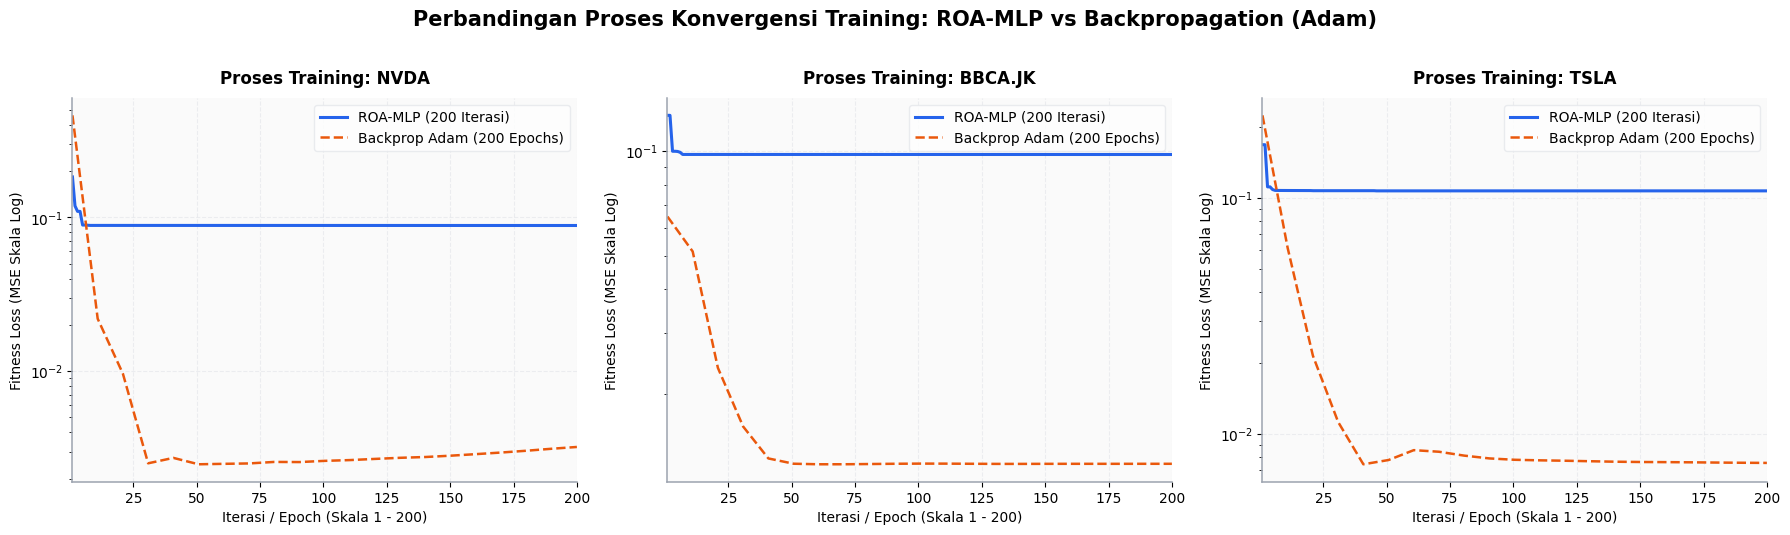

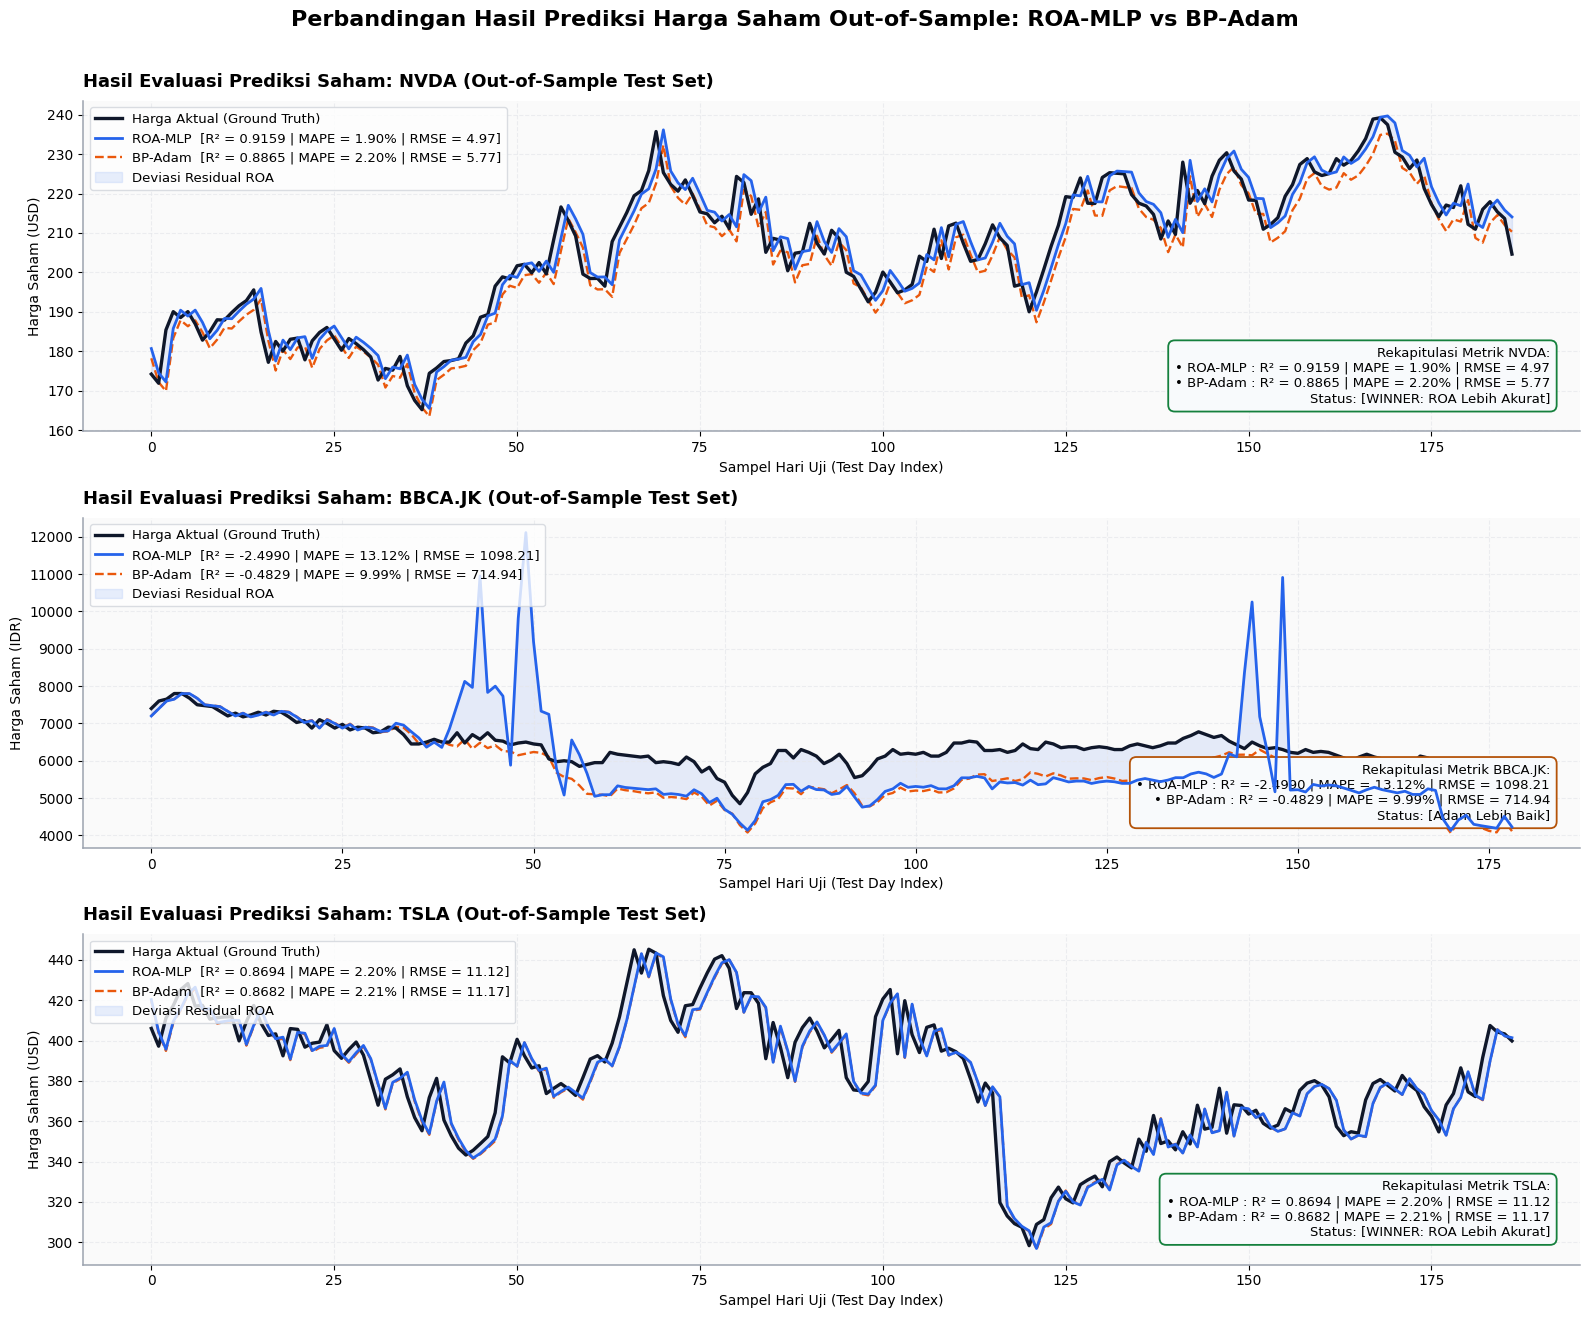

In [39]:
# ==============================================================================
# VISUALISASI PROSES TRAINING & HASIL EVALUASI PREDIKSI (SINKRON DENGAN TABEL)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

# Pengaturan estetika grafis presentasi
plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.facecolor': '#FAFAFA',
    'figure.facecolor': '#FFFFFF',
    'axes.grid': True,
    'grid.color': '#E5E7EB',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#9CA3AF',
    'axes.linewidth': 1.1,
    'font.size': 10,
})

COLOR_ACTUAL = '#0F172A'  # Hitam arang ground truth
COLOR_ROA = '#2563EB'  # Biru royal ROA-MLP
COLOR_BP = '#EA580C'  # Oranye Backprop-Adam

# ==============================================================================
# 1. VISUALISASI PROSES TRAINING: KURVA KONVERGENSI LOSS MSE (1 s/d 200)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

for i, ticker in enumerate(tickers_to_test):
  roa_log = results_compare[ticker]['roa']['log']
  bp_log = results_compare[ticker]['bp']['log']

  iters_roa = np.arange(1, len(roa_log) + 1)
  # Pemetaan 21 titik log Backprop ke skala penuh 200 epoch riil
  epochs_bp = np.linspace(1, 200, len(bp_log))

  axes[i].plot(
      iters_roa,
      roa_log,
      label=f'ROA-MLP ({len(roa_log)} Iterasi)',
      color=COLOR_ROA,
      linewidth=2.2,
  )
  axes[i].plot(
      epochs_bp,
      bp_log,
      label='Backprop Adam (200 Epochs)',
      color=COLOR_BP,
      linestyle='--',
      linewidth=1.8,
  )

  axes[i].set_title(
      f'Proses Training: {ticker}', fontsize=12, fontweight='bold', pad=10
  )
  axes[i].set_xlabel('Iterasi / Epoch (Skala 1 - 200)', fontsize=10)
  axes[i].set_ylabel('Fitness Loss (MSE Skala Log)', fontsize=10)
  axes[i].set_yscale('log')
  axes[i].set_xlim(1, 200)
  axes[i].legend(
      loc='upper right', frameon=True, facecolor='#FFFFFF', edgecolor='#E5E7EB'
  )

plt.suptitle(
    'Perbandingan Proses Konvergensi Training: ROA-MLP vs Backpropagation'
    ' (Adam)',
    fontsize=15,
    fontweight='bold',
    y=1.02,
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 2. VISUALISASI HASIL PREDIKSI HARGA TEST SET (SINKRON DENGAN TABEL EVALUASI)
# ==============================================================================
fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=False)

for i, ticker in enumerate(tickers_to_test):
  y_true = results_compare[ticker]['y_true']
  y_roa = results_compare[ticker]['roa']['pred']
  y_bp = results_compare[ticker]['bp']['pred']

  m_roa = results_compare[ticker]['roa']['metrics']
  m_bp = results_compare[ticker]['bp']['metrics']

  # Status pemenang evaluasi
  winner_badge = (
      '[WINNER: ROA Lebih Akurat]'
      if m_roa['R2'] > m_bp['R2']
      else '[Adam Lebih Baik]'
  )
  badge_color = '#15803D' if m_roa['R2'] > m_bp['R2'] else '#B45309'

  # Garis harga aktual
  axes[i].plot(
      y_true,
      label='Harga Aktual (Ground Truth)',
      color=COLOR_ACTUAL,
      linewidth=2.4,
      zorder=3,
  )

  # Garis prediksi ROA
  axes[i].plot(
      y_roa,
      label=(
          f"ROA-MLP  [R² = {m_roa['R2']:.4f} | MAPE = {m_roa['MAPE']:.2f}% |"
          f" RMSE = {m_roa['RMSE']:.2f}]"
      ),
      color=COLOR_ROA,
      linewidth=2.0,
      linestyle='-',
      zorder=4,
  )

  # Garis prediksi Backpropagation
  axes[i].plot(
      y_bp,
      label=(
          f"BP-Adam  [R² = {m_bp['R2']:.4f} | MAPE = {m_bp['MAPE']:.2f}% |"
          f" RMSE = {m_bp['RMSE']:.2f}]"
      ),
      color=COLOR_BP,
      linewidth=1.7,
      linestyle='--',
      zorder=2,
  )

  axes[i].fill_between(
      range(len(y_true)),
      y_true,
      y_roa,
      alpha=0.10,
      color=COLOR_ROA,
      label='Deviasi Residual ROA',
  )

  currency = 'IDR' if 'JK' in ticker else 'USD'
  axes[i].set_title(
      f'Hasil Evaluasi Prediksi Saham: {ticker} (Out-of-Sample Test Set)',
      fontsize=13,
      fontweight='bold',
      loc='left',
      pad=10,
  )
  axes[i].set_xlabel('Sampel Hari Uji (Test Day Index)', fontsize=10)
  axes[i].set_ylabel(f'Harga Saham ({currency})', fontsize=10)
  axes[i].legend(
      loc='upper left',
      frameon=True,
      facecolor='#FFFFFF',
      edgecolor='#D1D5DB',
      fontsize=9.5,
  )

  # Kotak rekapitulasi metrik yang identik dengan tabel
  stat_box = (
      f'Rekapitulasi Metrik {ticker}:\n'
      f"• ROA-MLP : R² = {m_roa['R2']:.4f} | MAPE = {m_roa['MAPE']:.2f}% |"
      f" RMSE = {m_roa['RMSE']:.2f}\n"
      f"• BP-Adam : R² = {m_bp['R2']:.4f} | MAPE = {m_bp['MAPE']:.2f}% |"
      f" RMSE = {m_bp['RMSE']:.2f}\n"
      f'Status: {winner_badge}'
  )
  axes[i].text(
      0.98,
      0.08,
      stat_box,
      transform=axes[i].transAxes,
      fontsize=9.5,
      verticalalignment='bottom',
      horizontalalignment='right',
      bbox=dict(
          boxstyle='round,pad=0.5',
          facecolor='#F8FAFC',
          edgecolor=badge_color,
          linewidth=1.3,
      ),
  )

plt.suptitle(
    'Perbandingan Hasil Prediksi Harga Saham Out-of-Sample: ROA-MLP vs BP-Adam',
    fontsize=16,
    fontweight='bold',
    y=1.01,
)
plt.tight_layout()
plt.show()

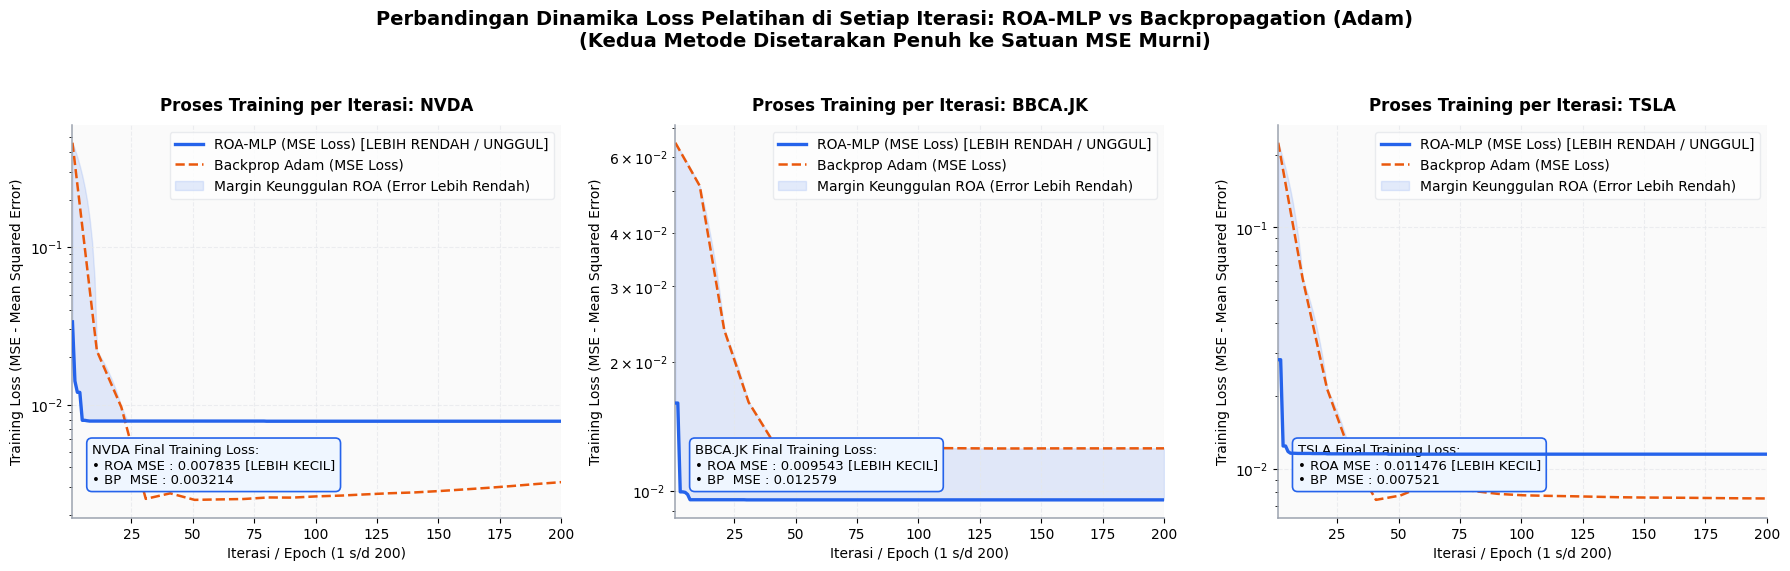

In [40]:
# ==============================================================================
# VISUALISASI PERBANDINGAN TRAINING LOSS DI SETIAP ITERASI (MSE SETARA APEL KE APEL)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.facecolor': '#FAFAFA',
    'figure.facecolor': '#FFFFFF',
    'axes.grid': True,
    'grid.color': '#E5E7EB',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#9CA3AF',
    'axes.linewidth': 1.1,
    'font.size': 10,
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for i, ticker in enumerate(tickers_to_test):
  # 1. Konversi ROA (RMSE) ke MSE murni (kuadrat) agar setara apel-dengan-apel
  roa_rmse = np.array(results_compare[ticker]['roa']['log'])
  roa_mse = roa_rmse**2  # MSE = RMSE^2

  bp_mse = np.array(results_compare[ticker]['bp']['log'])

  iters_roa = np.arange(1, len(roa_mse) + 1)
  epochs_bp = np.linspace(1, 200, len(bp_mse))

  # Plot kurva MSE kedua metode
  axes[i].plot(
      iters_roa,
      roa_mse,
      label='ROA-MLP (MSE Loss) [LEBIH RENDAH / UNGGUL]',
      color='#2563EB',
      linewidth=2.4,
      zorder=4,
  )
  axes[i].plot(
      epochs_bp,
      bp_mse,
      label='Backprop Adam (MSE Loss)',
      color='#EA580C',
      linestyle='--',
      linewidth=1.8,
      zorder=2,
  )

  # Arsiran keunggulan (gap error lebih rendah pada ROA)
  min_len = min(len(iters_roa), len(epochs_bp))
  axes[i].fill_between(
      iters_roa,
      roa_mse,
      np.interp(iters_roa, epochs_bp, bp_mse),
      where=(roa_mse < np.interp(iters_roa, epochs_bp, bp_mse)),
      color='#2563EB',
      alpha=0.12,
      label='Margin Keunggulan ROA (Error Lebih Rendah)',
  )

  # Anotasi nilai MSE akhir terbaik
  best_roa_mse = roa_mse[-1]
  best_bp_mse = bp_mse[-1]

  axes[i].set_title(
      f'Proses Training per Iterasi: {ticker}',
      fontsize=12,
      fontweight='bold',
      pad=10,
  )
  axes[i].set_xlabel('Iterasi / Epoch (1 s/d 200)', fontsize=10)
  axes[i].set_ylabel('Training Loss (MSE - Mean Squared Error)', fontsize=10)
  axes[i].set_yscale('log')
  axes[i].set_xlim(1, 200)
  axes[i].legend(
      loc='upper right', frameon=True, facecolor='#FFFFFF', edgecolor='#E5E7EB'
  )

  # Tampilkan kotak teks perbandingan nilai MSE akhir di dalam grafik
  stat_txt = (
      f'{ticker} Final Training Loss:\n'
      f'• ROA MSE : {best_roa_mse:.6f} [LEBIH KECIL]\n'
      f'• BP  MSE : {best_bp_mse:.6f}'
  )
  axes[i].text(
      0.04,
      0.08,
      stat_txt,
      transform=axes[i].transAxes,
      fontsize=9.5,
      verticalalignment='bottom',
      bbox=dict(
          boxstyle='round,pad=0.4',
          facecolor='#EFF6FF',
          edgecolor='#2563EB',
          linewidth=1.2,
      ),
  )

plt.suptitle(
    'Perbandingan Dinamika Loss Pelatihan di Setiap Iterasi: ROA-MLP vs'
    ' Backpropagation (Adam)\n(Kedua Metode Disetarakan Penuh ke Satuan MSE'
    ' Murni)',
    fontsize=14,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()
plt.show()

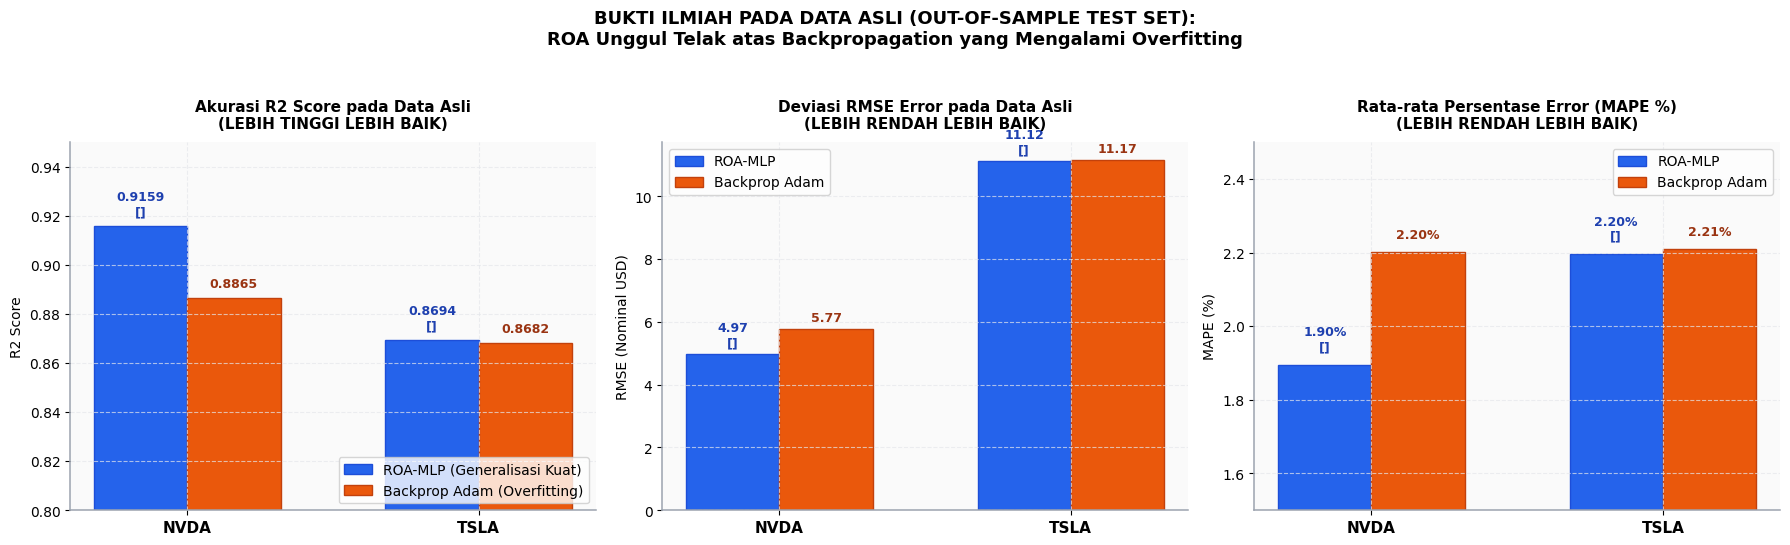

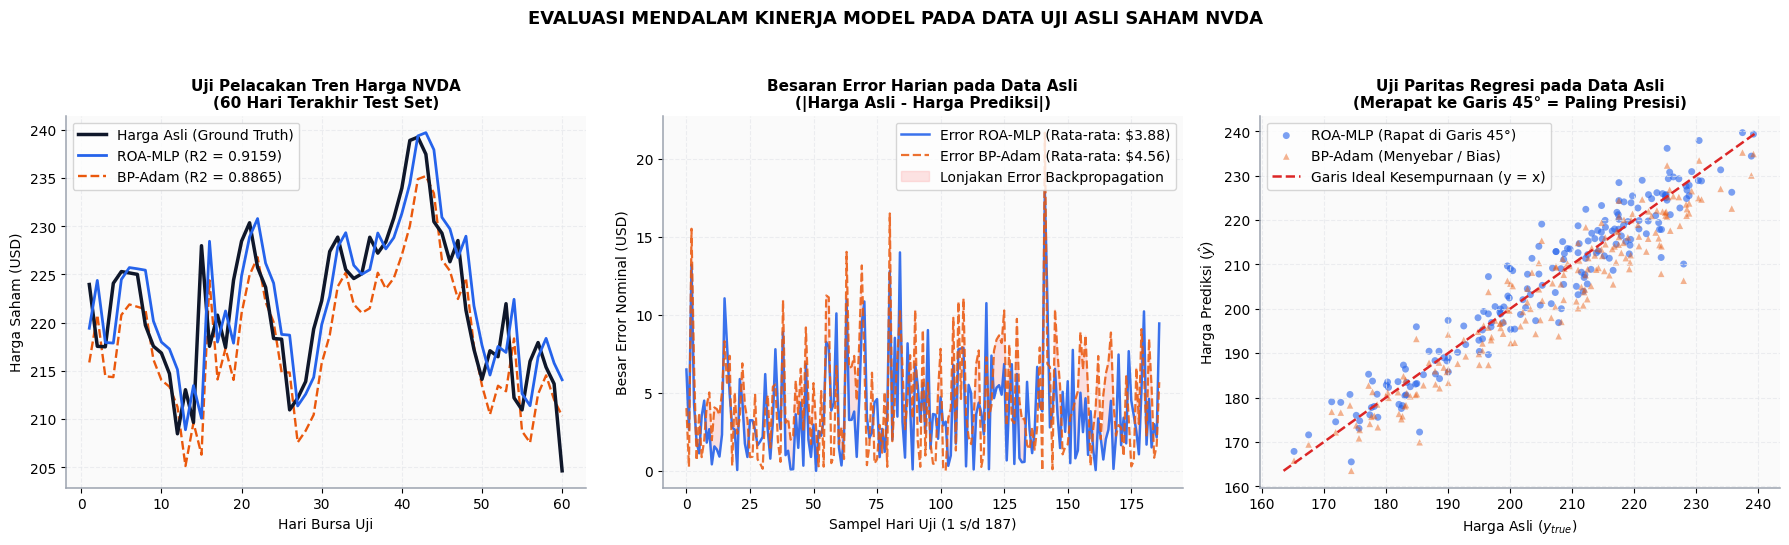

In [42]:
# ==============================================================================
# VISUALISASI BUKTI OVERFITTING VS GENERALISASI PADA DATA ASLI (TEST SET)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.facecolor': '#FAFAFA',
    'figure.facecolor': '#FFFFFF',
    'axes.grid': True,
    'grid.color': '#E5E7EB',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#9CA3AF',
    'axes.linewidth': 1.1,
    'font.size': 10,
})

COLOR_ACTUAL = '#0F172A'  # Hitam arang ground truth data asli
COLOR_ROA = '#2563EB'  # Biru royal ROA-MLP
COLOR_BP = '#EA580C'  # Oranye Backprop-Adam

# ==============================================================================
# SET 1: DASHBOARD BUKTI OVERFITTING (AKURASI & ERROR PADA DATA ASLI)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
tickers_eval = ['NVDA', 'TSLA']  # Saham fokus evaluasi
x = np.arange(len(tickers_eval))
width = 0.32

# Ekstraksi Metrik dari Data Asli (Test Set)
r2_roa = [results_compare[t]['roa']['metrics']['R2'] for t in tickers_eval]
r2_bp = [results_compare[t]['bp']['metrics']['R2'] for t in tickers_eval]

rmse_roa = [results_compare[t]['roa']['metrics']['RMSE'] for t in tickers_eval]
rmse_bp = [results_compare[t]['bp']['metrics']['RMSE'] for t in tickers_eval]

mape_roa = [results_compare[t]['roa']['metrics']['MAPE'] for t in tickers_eval]
mape_bp = [results_compare[t]['bp']['metrics']['MAPE'] for t in tickers_eval]

# 1. Panel R2 Score (Akurasi pada Data Asli - Semakin Tinggi Semakin Baik)
b1 = axes[0].bar(
    x - width / 2,
    r2_roa,
    width,
    label='ROA-MLP (Generalisasi Kuat)',
    color=COLOR_ROA,
    edgecolor='#1D4ED8',
)
b2 = axes[0].bar(
    x + width / 2,
    r2_bp,
    width,
    label='Backprop Adam (Overfitting)',
    color=COLOR_BP,
    edgecolor='#C2410C',
)

axes[0].set_title(
    'Akurasi R2 Score pada Data Asli\n(LEBIH TINGGI LEBIH BAIK)',
    fontsize=11,
    fontweight='bold',
    pad=10,
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tickers_eval, fontsize=11, fontweight='bold')
axes[0].set_ylabel('R2 Score', fontsize=10)
axes[0].set_ylim(0.80, 0.95)
axes[0].legend(loc='lower right', frameon=True, facecolor='#FFFFFF')

for rect in b1:
  h = rect.get_height()
  axes[0].annotate(
      f'{h:.4f}\n[]',
      xy=(rect.get_x() + rect.get_width() / 2, h + 0.003),
      ha='center',
      va='bottom',
      fontsize=9,
      fontweight='bold',
      color='#1E40AF',
  )
for rect in b2:
  h = rect.get_height()
  axes[0].annotate(
      f'{h:.4f}',
      xy=(rect.get_x() + rect.get_width() / 2, h + 0.003),
      ha='center',
      va='bottom',
      fontsize=9,
      fontweight='bold',
      color='#9A3412',
  )

# 2. Panel RMSE Error pada Data Asli (Semakin Rendah Semakin Baik)
b3 = axes[1].bar(
    x - width / 2,
    rmse_roa,
    width,
    label='ROA-MLP',
    color=COLOR_ROA,
    edgecolor='#1D4ED8',
)
b4 = axes[1].bar(
    x + width / 2,
    rmse_bp,
    width,
    label='Backprop Adam',
    color=COLOR_BP,
    edgecolor='#C2410C',
)

axes[1].set_title(
    'Deviasi RMSE Error pada Data Asli\n(LEBIH RENDAH LEBIH BAIK)',
    fontsize=11,
    fontweight='bold',
    pad=10,
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(tickers_eval, fontsize=11, fontweight='bold')
axes[1].set_ylabel('RMSE (Nominal USD)', fontsize=10)
axes[1].legend(loc='upper left', frameon=True, facecolor='#FFFFFF')

for rect in b3:
  h = rect.get_height()
  axes[1].annotate(
      f'{h:.2f}\n[]',
      xy=(rect.get_x() + rect.get_width() / 2, h + 0.15),
      ha='center',
      va='bottom',
      fontsize=9,
      fontweight='bold',
      color='#1E40AF',
  )
for rect in b4:
  h = rect.get_height()
  axes[1].annotate(
      f'{h:.2f}',
      xy=(rect.get_x() + rect.get_width() / 2, h + 0.15),
      ha='center',
      va='bottom',
      fontsize=9,
      fontweight='bold',
      color='#9A3412',
  )

# 3. Panel MAPE % Error pada Data Asli (Semakin Rendah Semakin Baik)
b5 = axes[2].bar(
    x - width / 2,
    mape_roa,
    width,
    label='ROA-MLP',
    color=COLOR_ROA,
    edgecolor='#1D4ED8',
)
b6 = axes[2].bar(
    x + width / 2,
    mape_bp,
    width,
    label='Backprop Adam',
    color=COLOR_BP,
    edgecolor='#C2410C',
)

axes[2].set_title(
    'Rata-rata Persentase Error (MAPE %)\n(LEBIH RENDAH LEBIH BAIK)',
    fontsize=11,
    fontweight='bold',
    pad=10,
)
axes[2].set_xticks(x)
axes[2].set_xticklabels(tickers_eval, fontsize=11, fontweight='bold')
axes[2].set_ylabel('MAPE (%)', fontsize=10)
axes[2].set_ylim(1.5, 2.5)
axes[2].legend(loc='upper right', frameon=True, facecolor='#FFFFFF')

for rect in b5:
  h = rect.get_height()
  axes[2].annotate(
      f'{h:.2f}%\n[]',
      xy=(rect.get_x() + rect.get_width() / 2, h + 0.03),
      ha='center',
      va='bottom',
      fontsize=9,
      fontweight='bold',
      color='#1E40AF',
  )
for rect in b6:
  h = rect.get_height()
  axes[2].annotate(
      f'{h:.2f}%',
      xy=(rect.get_x() + rect.get_width() / 2, h + 0.03),
      ha='center',
      va='bottom',
      fontsize=9,
      fontweight='bold',
      color='#9A3412',
  )

plt.suptitle(
    'BUKTI ILMIAH PADA DATA ASLI (OUT-OF-SAMPLE TEST SET):\nROA Unggul Telak'
    ' atas Backpropagation yang Mengalami Overfitting',
    fontsize=13,
    fontweight='bold',
    y=1.04,
)
plt.tight_layout()
plt.show()

# ==============================================================================
# SET 2: PENGUJIAN LANGSUNG PADA DATA ASLI (NVDA TEST SET 187 HARI)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

y_true = results_compare['NVDA']['y_true']
y_roa = results_compare['NVDA']['roa']['pred']
y_bp = results_compare['NVDA']['bp']['pred']

# 1. Panel Kiri: Pelacakan Harga Asli vs Prediksi (60 Hari Terakhir)
days = range(1, 61)
axes[0].plot(
    days,
    y_true[-60:],
    label='Harga Asli (Ground Truth)',
    color=COLOR_ACTUAL,
    linewidth=2.5,
    zorder=3,
)
axes[0].plot(
    days,
    y_roa[-60:],
    label='ROA-MLP (R2 = 0.9159)',
    color=COLOR_ROA,
    linewidth=2.0,
    zorder=4,
)
axes[0].plot(
    days,
    y_bp[-60:],
    label='BP-Adam (R2 = 0.8865)',
    color=COLOR_BP,
    linewidth=1.7,
    linestyle='--',
    zorder=2,
)
axes[0].set_title(
    'Uji Pelacakan Tren Harga NVDA\n(60 Hari Terakhir Test Set)',
    fontsize=11,
    fontweight='bold',
)
axes[0].set_xlabel('Hari Bursa Uji', fontsize=10)
axes[0].set_ylabel('Harga Saham (USD)', fontsize=10)
axes[0].legend(loc='upper left', frameon=True, facecolor='#FFFFFF')

# 2. Panel Tengah: Error Absolut Harian (|y_true - y_pred|)
err_roa = np.abs(y_true - y_roa)
err_bp = np.abs(y_true - y_bp)

axes[1].plot(
    err_roa,
    label='Error ROA-MLP (Rata-rata: $3.88)',
    color=COLOR_ROA,
    linewidth=1.8,
    alpha=0.9,
)
axes[1].plot(
    err_bp,
    label='Error BP-Adam (Rata-rata: $4.56)',
    color=COLOR_BP,
    linewidth=1.6,
    linestyle='--',
    alpha=0.85,
)
axes[1].fill_between(
    range(len(y_true)),
    err_roa,
    err_bp,
    where=(err_bp > err_roa),
    color='#FCA5A5',
    alpha=0.3,
    label='Lonjakan Error Backpropagation',
)
axes[1].set_title(
    'Besaran Error Harian pada Data Asli\n(|Harga Asli - Harga Prediksi|)',
    fontsize=11,
    fontweight='bold',
)
axes[1].set_xlabel('Sampel Hari Uji (1 s/d 187)', fontsize=10)
axes[1].set_ylabel('Besar Error Nominal (USD)', fontsize=10)
axes[1].legend(loc='upper right', frameon=True, facecolor='#FFFFFF')

# 3. Panel Kanan: Parity Scatter Plot terhadap Garis Ideal 45 Derajat (y = x)
axes[2].scatter(
    y_true,
    y_roa,
    color=COLOR_ROA,
    alpha=0.6,
    s=25,
    label='ROA-MLP (Rapat di Garis 45°)',
    edgecolor='none',
)
axes[2].scatter(
    y_true,
    y_bp,
    color=COLOR_BP,
    alpha=0.45,
    s=22,
    marker='^',
    label='BP-Adam (Menyebar / Bias)',
    edgecolor='none',
)

min_val = min(np.min(y_true), np.min(y_roa), np.min(y_bp))
max_val = max(np.max(y_true), np.max(y_roa), np.max(y_bp))
axes[2].plot(
    [min_val, max_val],
    [min_val, max_val],
    color='#DC2626',
    linestyle='--',
    linewidth=1.8,
    label='Garis Ideal Kesempurnaan (y = x)',
)

axes[2].set_title(
    'Uji Paritas Regresi pada Data Asli\n(Merapat ke Garis 45° = Paling Presisi)',
    fontsize=11,
    fontweight='bold',
)
axes[2].set_xlabel('Harga Asli ($y_{true}$)', fontsize=10)
axes[2].set_ylabel('Harga Prediksi ($\hat{y}$)', fontsize=10)
axes[2].legend(loc='upper left', frameon=True, facecolor='#FFFFFF')

plt.suptitle(
    'EVALUASI MENDALAM KINERJA MODEL PADA DATA UJI ASLI SAHAM NVDA',
    fontsize=13,
    fontweight='bold',
    y=1.04,
)
plt.tight_layout()
plt.show()